# Federated fraud detection with a cardholder e-mail verification loop

This notebook implements the architecture in your diagram, one cell per block:

| Cell | Diagram block |
|---|---|
| 1 | Settings and imports |
| 2 | 1-3: raw data, **sequencing**, local banks (privacy boundary) |
| 3 | 5: **contrastive transformer** (supervised-contrastive loss) |
| 4 | 4: global server with **secure aggregation** and a **model registry** |
| 5 | 6: real-time decision with **T_low / T_high** (auto-approve, uncertain, block) |
| 6 | 7: **explainable-AI** layer (gradient x input reasons) |
| 7 | 8: **user message** by Gmail and **user response** (Confirm / Deny) |
| 8 | **Feedback loop**: continual learning with the answers, plus a no-feedback control |
| 9 | Save tables and figures |
| 10 | **Multi-seed benchmark**: centralised HGB / transformer, local-only, FedAvg, FedAvg+SupCon, feedback vs control, XAI test, paired differences |
| 11 | **Paper figures** (A-I) and `paper_numbers.json`, zipped to `pipeline_results.zip` |

**How to run**
1. Put `creditcard.csv` next to this notebook (or change `DATA_PATH`).
2. Run cell 1 with `QUICK = True` first (about 1-2 minutes) to check that everything works, then set `QUICK = False` and run all cells.
3. Cell 7 runs in **DRY-RUN** mode by default (replies are simulated). To send real Gmail messages set `LIVE_EMAIL = True` in cell 1 and follow the instructions printed by cell 7. Never type your password into the file.

**Honest notes (they are also in the paper)**
* `creditcard.csv` has no card or customer id, so a "sequence" is a window of the L most recent transactions of the same bank in time order. It is a pseudo-sequence, not a true customer history.
* Secure aggregation here is a **simulation** of pairwise additive masking: the server only sees masked updates and recovers the exact weighted average. A real deployment also needs key agreement and dropout handling.
* With a live run, you are the cardholder and you see only the amount, time and reasons, so your answers will not always agree with the dataset label. They are logged and also used as feedback, but the quantitative before/after comparison uses the simulated user (response rate and accuracy in cell 1).

In [7]:
# ============================== CELL 1: SETTINGS ==============================
import os, sys, time, json, copy, math, re, ssl, smtplib, imaplib, hashlib, getpass
from email.message import EmailMessage
from email.header import decode_header, make_header
from email.utils import parseaddr
from urllib.parse import quote
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (average_precision_score, roc_auc_score, f1_score, matthews_corrcoef,
                             precision_score, recall_score, precision_recall_curve)

QUICK       = True        # True = smoke test (tiny budget). Set False for the real run.
DATA_PATH   = "creditcard.csv"
OUT_DIR     = "results_pipeline"
SEED        = 0

N_BANKS     = 3           # local banks / clients
DIRICHLET   = 0.5         # non-IID skew (small = more skewed)
SEQ_LEN     = 8           # transactions per sequence window
ROUNDS      = 15          # federated rounds
LOCAL_EPOCHS= 1
BATCH       = 512         # 25 % of every batch is fraud (class-balanced sampling)
LR          = 1e-3
SUPCON_W    = 0.5         # weight of the supervised-contrastive loss
D_MODEL, N_HEAD, N_LAYERS, EMB = 32, 4, 2, 16

MISS_BUDGET = 0.02        # T_low: at most 2 % of validation frauds may be auto-approved
FB_ROUNDS   = 5           # extra federated rounds after feedback (and for the control)
USER_RESPONSE, USER_ACCURACY = 0.6, 0.95   # simulated cardholder
STEP_CAP    = None        # max local steps per round (None = full epoch)

# ----- e-mail (cell 7) -----
LIVE_EMAIL  = False       # False = DRY RUN (simulated replies). True = real Gmail messages.
N_LIVE      = 6           # how many real e-mails to send
WAIT_SECONDS= 600         # how long to wait for your replies
POLL_EVERY  = 5
GMAIL_USER  = os.environ.get("GMAIL_USER", "")          # e.g. yourname@gmail.com
# the app password is read from the environment variable GMAIL_APP_PASSWORD or typed (hidden) when prompted

if QUICK:
    ROUNDS, FB_ROUNDS, STEP_CAP, N_LIVE, WAIT_SECONDS = 2, 1, 30, 3, 180
os.makedirs(OUT_DIR, exist_ok=True)
DEV = torch.device("cuda" if torch.cuda.is_available() else "cpu")
np.random.seed(SEED); torch.manual_seed(SEED); rng = np.random.default_rng(SEED)
print("device:", DEV, "| QUICK:", QUICK, "| LIVE_EMAIL:", LIVE_EMAIL)

device: cpu | QUICK: True | LIVE_EMAIL: False


In [9]:
# ============ CELL 2: RAW DATA -> PROCESSING & SEQUENCING -> LOCAL BANKS ============
df = pd.read_csv(DATA_PATH); df.columns = df.columns.str.strip()
df = df.drop_duplicates().sort_values("Time", kind="stable").reset_index(drop=True)
y_all = df["Class"].values.astype(int)
FEATURE_NAMES = [f"V{i}" for i in range(1, 29)] + ["log_Amount", "tod_sin", "tod_cos"]
tod = (df["Time"].values % 86400) / 86400 * 2 * np.pi
X_raw = np.hstack([df[[f"V{i}" for i in range(1, 29)]].values, np.log1p(df["Amount"].values)[:, None],
                   np.sin(tod)[:, None], np.cos(tod)[:, None]]).astype(np.float32)
print(f"rows={len(df):,}  frauds={y_all.sum()} ({y_all.mean()*100:.3f}%)")

# stratified split: train / validation (thresholds) / feedback pool (cardholder alerts) / test (never used for fitting)
idx = np.arange(len(df))
tr, te = train_test_split(idx, test_size=0.20, stratify=y_all, random_state=SEED)
tr, va = train_test_split(tr, test_size=0.15, stratify=y_all[tr], random_state=SEED)
tr, pool = train_test_split(tr, test_size=0.20, stratify=y_all[tr], random_state=SEED)
scaler = StandardScaler().fit(X_raw[tr])                  # fitted on training data only
X = scaler.transform(X_raw).astype(np.float32)

def partition(ids, n_banks, alpha, rng, min_fraud=10):    # non-IID Dirichlet allocation per class
    for _ in range(200):
        banks = [[] for _ in range(n_banks)]
        for cls in (0, 1):
            ci = ids[y_all[ids] == cls].copy(); rng.shuffle(ci)
            cuts = (np.cumsum(rng.dirichlet(alpha * np.ones(n_banks))) * len(ci)).astype(int)[:-1]
            for b, part in enumerate(np.split(ci, cuts)): banks[b] += part.tolist()
        if all(y_all[np.array(b, dtype=int)].sum() >= min_fraud for b in banks): break
    return [np.sort(np.array(b, dtype=int)) for b in banks]

def make_seq(ids, L=SEQ_LEN):
    """Sequencing: for each transaction, the window of the L latest transactions of the SAME bank/split
    (time order, left-padded with the first row). Returns (windows, labels, sorted ids)."""
    ids = np.sort(ids); n = len(ids)
    pos = np.clip(np.arange(n)[:, None] + np.arange(-L + 1, 1)[None, :], 0, None)
    return X[ids][pos], y_all[ids], ids

bank_ids = partition(tr, N_BANKS, DIRICHLET, rng)
BANKS = [make_seq(b) for b in bank_ids]          # each bank keeps its data; only weights leave
VAL, POOL, TEST = make_seq(va), make_seq(pool), make_seq(te)
for i, (S, y, _) in enumerate(BANKS): print(f"  bank {i+1}: n={len(y):,} frauds={int(y.sum())}")
print(f"  val n={len(VAL[1]):,} (fraud {VAL[1].sum()}) | pool n={len(POOL[1]):,} (fraud {POOL[1].sum()}) | test n={len(TEST[1]):,} (fraud {TEST[1].sum()})")
D_IN = X.shape[1]

rows=283,726  frauds=473 (0.167%)
  bank 1: n=128,430 frauds=168
  bank 2: n=24,100 frauds=77
  bank 3: n=1,816 frauds=12
  val n=34,047 (fraud 57) | pool n=38,587 (fraud 64) | test n=56,746 (fraud 95)


In [11]:
# ============ CELL 3: CONTRASTIVE TRANSFORMER (per-bank model) ============
class SeqNet(nn.Module):
    """Transformer encoder over a window of transactions. The embedding z of the last transaction is
    trained with a supervised-contrastive loss; a linear head gives the fraud logit."""
    def __init__(self, d_in=D_IN, d=D_MODEL, heads=N_HEAD, layers=N_LAYERS, emb=EMB, L=SEQ_LEN):
        super().__init__()
        self.inp = nn.Linear(d_in, d)
        self.pos = nn.Parameter(torch.zeros(1, L, d))
        layer = nn.TransformerEncoderLayer(d, heads, 64, 0.1, activation="gelu", batch_first=True, norm_first=True)
        self.enc = nn.TransformerEncoder(layer, layers, enable_nested_tensor=False)
        self.ln, self.proj, self.head = nn.LayerNorm(d), nn.Linear(d, emb), nn.Linear(emb, 1)
    def forward(self, x):                        # x: (B, L, D)
        h = self.enc(self.inp(x) + self.pos)
        z = self.proj(self.ln(h[:, -1, :]))
        return self.head(F.leaky_relu(z, 0.1)).squeeze(-1), z

def supcon_loss(z, y, T=0.1):
    z = F.normalize(z, dim=1); sim = z @ z.T / T
    eye = torch.eye(len(z), dtype=torch.bool, device=z.device)
    sim = sim.masked_fill(eye, -1e9)
    logp = sim - torch.logsumexp(sim, dim=1, keepdim=True)
    pos = (y[:, None] == y[None, :]) & ~eye
    cnt = pos.sum(1); ok = cnt > 0
    if not ok.any(): return z.sum() * 0
    return (-(logp * pos).sum(1)[ok] / cnt[ok]).mean()

def local_train(model, S, y, epochs=LOCAL_EPOCHS, supcon_w=SUPCON_W):
    model.train(); opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
    pos, neg = np.where(y == 1)[0], np.where(y == 0)[0]
    steps = max(1, math.ceil(len(y) / BATCH)) * epochs
    if STEP_CAP: steps = min(steps, STEP_CAP)
    for _ in range(steps):
        npos = BATCH // 4 if len(pos) > 0 else 0               # class-balanced sampling
        b = np.concatenate([np.random.choice(pos, npos) if npos else np.array([], dtype=int),
                            np.random.choice(neg, BATCH - npos)])
        bx = torch.from_numpy(S[b]).to(DEV); by = torch.from_numpy(y[b].astype(np.float32)).to(DEV)
        logit, z = model(bx)
        loss = F.binary_cross_entropy_with_logits(logit, by)
        if supcon_w > 0: loss = loss + supcon_w * supcon_loss(z, by)
        opt.zero_grad(); loss.backward(); opt.step()
    return model

@torch.no_grad()
def predict(model, S, bs=4096):
    model.eval(); out = []
    for i in range(0, len(S), bs):
        out.append(torch.sigmoid(model(torch.from_numpy(S[i:i + bs]).to(DEV))[0]).cpu().numpy())
    return np.concatenate(out)

def pick_threshold(y, s):                                       # max-F1 threshold on VALIDATION
    p, r, t = precision_recall_curve(y, s)
    return float(t[np.argmax(2 * p[:-1] * r[:-1] / (p[:-1] + r[:-1] + 1e-12))])

def metrics(y, s, thr):
    pred = (s >= thr).astype(int)
    return {"PR-AUC": average_precision_score(y, s), "ROC-AUC": roc_auc_score(y, s),
            "Precision": precision_score(y, pred, zero_division=0), "Recall": recall_score(y, pred, zero_division=0),
            "F1": f1_score(y, pred, zero_division=0), "MCC": matthews_corrcoef(y, pred), "Alerts/100k": pred.mean() * 1e5}
print("parameters per model:", sum(p.numel() for p in SeqNet().parameters()))

parameters per model: 18977


In [13]:
# ============ CELL 4: GLOBAL SERVER = SECURE AGGREGATOR + MODEL REGISTRY ============
def flat(sd):   return np.concatenate([v.detach().cpu().numpy().astype(np.float64).ravel() for v in sd.values()])
def unflat(vec, ref):
    out, i = {}, 0
    for k, v in ref.items():
        n = v.numel(); out[k] = torch.from_numpy(vec[i:i + n].reshape(tuple(v.shape))).to(v.dtype); i += n
    return out

def _pair_mask(i, j, rnd, size, secret):                         # shared secret of the pair (i, j)
    return np.random.default_rng([secret, rnd, i, j]).normal(0.0, 1.0, size)

def secure_aggregate(vecs, sizes, rnd, secret=12345):
    """Pairwise additive masking: bank k sends  (n_k/n) w_k + sum_{j>k} m_kj - sum_{j<k} m_jk.
    The masks cancel in the sum, so the server learns only the weighted average, never one bank's update."""
    K, n = len(vecs), float(sum(sizes)); masked = []
    for k in range(K):
        u = vecs[k] * (sizes[k] / n)
        for j in range(K):
            if j == k: continue
            m = _pair_mask(min(k, j), max(k, j), rnd, u.size, secret)
            u = u + (m if k < j else -m)
        masked.append(u)
    return np.sum(masked, axis=0), masked

REGISTRY = []
def run_federation(gm, bank_sets, rounds, supcon_w, tag, start=0, verbose=True):
    """FedAvg with secure aggregation; every aggregated global model is registered (version, hash, size)."""
    for r in range(rounds):
        vecs, sizes = [], []
        for S, y, *_ in bank_sets:
            lm = copy.deepcopy(gm); local_train(lm, S, y, supcon_w=supcon_w)
            vecs.append(flat(lm.state_dict())); sizes.append(len(y))
        agg, masked = secure_aggregate(vecs, sizes, start + r)
        if r == 0 and verbose:   # sanity check: secure result equals plain FedAvg, and masked updates hide the real ones
            plain = sum(v * (s / sum(sizes)) for v, s in zip(vecs, sizes))
            print(f"  [secure-agg check] max|secure - plain| = {np.abs(agg - plain).max():.2e}; "
                  f"masked/real update norm ratio = {np.linalg.norm(masked[0]) / np.linalg.norm(vecs[0] * sizes[0] / sum(sizes)):.1f}x")
        gm.load_state_dict(unflat(agg, gm.state_dict()))
        REGISTRY.append({"tag": tag, "round": r + 1, "sha256": hashlib.sha256(agg.astype(np.float32).tobytes()).hexdigest()[:16],
                         "n_params": int(agg.size), "banks": len(bank_sets)})
        if verbose: print(f"  [{tag}] round {r+1}/{rounds} done  (registry v{len(REGISTRY)}: {REGISTRY[-1]['sha256']})")
    return gm

t0 = time.time()
print("Training the federation (transformer + supervised-contrastive loss) ...")
GM = run_federation(SeqNet().to(DEV), BANKS, ROUNDS, SUPCON_W, "base")
s_val, s_test = predict(GM, VAL[0]), predict(GM, TEST[0])
THR = pick_threshold(VAL[1], s_val)
base_metrics = metrics(TEST[1], s_test, THR)
print(f"done in {time.time()-t0:.0f}s | test PR-AUC={base_metrics['PR-AUC']:.3f} ROC-AUC={base_metrics['ROC-AUC']:.3f} "
      f"P={base_metrics['Precision']:.3f} R={base_metrics['Recall']:.3f} F1={base_metrics['F1']:.3f}")

Training the federation (transformer + supervised-contrastive loss) ...
  [secure-agg check] max|secure - plain| = 9.71e-16; masked/real update norm ratio = 12.3x
  [base] round 1/2 done  (registry v1: d8461765f75b7702)
  [base] round 2/2 done  (registry v2: 6b515165186b6794)
done in 26s | test PR-AUC=0.765 ROC-AUC=0.978 P=0.719 R=0.674 F1=0.696


In [15]:
# ============ CELL 5: REAL-TIME IDS & DECISION  (T_low / T_high) ============
def pick_T_low(y, s, miss=MISS_BUDGET):
    """Largest score below which at most `miss` of the validation frauds lie (safe to auto-approve)."""
    f = np.sort(s[y == 1]); return float(f[int(math.floor(miss * len(f)))]) if len(f) else 0.0

def thresholds(y_val, s_val):
    t_high = pick_threshold(y_val, s_val); t_low = pick_T_low(y_val, s_val)
    if t_low >= t_high: t_low = t_high * 0.5
    return t_low, t_high

def zones(s, t_low, t_high):
    return np.where(s < t_low, "auto-approve", np.where(s >= t_high, "block", "uncertain"))

def zone_report(y, s, t_low, t_high):
    z = zones(s, t_low, t_high); rows = []
    for name in ["auto-approve", "uncertain", "block"]:
        m = z == name
        rows.append({"zone": name, "transactions/100k": m.mean() * 1e5, "frauds": int(y[m].sum()),
                     "fraud share in zone": (y[m].mean() if m.any() else np.nan),
                     "share of all frauds": (y[m].sum() / max(1, y.sum()))})
    return pd.DataFrame(rows).set_index("zone")

T_LOW, T_HIGH = thresholds(VAL[1], s_val)
print(f"T_low={T_LOW:.4f}  T_high={T_HIGH:.4f}   (chosen on validation only)")
ZR_BASE = zone_report(TEST[1], s_test, T_LOW, T_HIGH)
display(ZR_BASE.style.format({"transactions/100k": "{:.0f}", "fraud share in zone": "{:.4f}", "share of all frauds": "{:.3f}"}))
print("Auto-approve = no message. Block and uncertain transactions go to the XAI layer and to the cardholder.")

T_low=0.0505  T_high=0.5864   (chosen on validation only)


,transactions/100k,frauds,fraud share in zone,share of all frauds
zone,,,,
auto-approve,17413,0,0.0000,0.000
uncertain,82430,31,0.0007,0.326
block,157,64,0.7191,0.674


Auto-approve = no message. Block and uncertain transactions go to the XAI layer and to the cardholder.


In [17]:
# ============ CELL 6: EXPLAINABLE AI LAYER (gradient x input) ============
def attribute(model, S):
    """Gradient x input of the fraud logit w.r.t. the features of the transaction being scored (last token)."""
    model.eval(); x = torch.from_numpy(S).to(DEV).requires_grad_(True)
    model(x)[0].sum().backward()
    return (x.grad * x)[:, -1, :].detach().cpu().numpy()

def reasons_for(model, S, ids, k=3):
    A = attribute(model, S); out = []
    for a, ix in zip(A, ids):
        txt = []
        for f in np.argsort(-np.abs(a))[:k]:
            name, z = FEATURE_NAMES[f], float(X[ix, f])
            if name == "log_Amount":      r = f"unusual amount ({df['Amount'].values[ix]:.2f})"
            elif name.startswith("tod_"): r = "unusual time of day"
            else:                         r = f"{'unusually high' if z > 0 else 'unusually low'} component {name} ({z:+.1f} SD)"
            if r not in txt: txt.append(r)
        out.append(txt)
    return out

def faithfulness(model, S, k=3):
    """Deletion test: zero the top-k attributed features vs. k random features; a faithful explanation
    lowers the fraud score much more than random deletion."""
    A = attribute(model, S)[:, :]; base = predict(model, S); n = len(S)
    top = np.argsort(-np.abs(A), axis=1)[:, :k]; rnd = np.stack([np.random.choice(D_IN, k, replace=False) for _ in range(n)])
    out = []
    for cols in (top, rnd):
        S2 = S.copy(); S2[np.arange(n)[:, None], -1, cols] = 0.0
        out.append(float((base - predict(model, S2)).mean()))
    return out

hit = np.where((TEST[1] == 1) & (s_test >= T_HIGH))[0][:1000]
if len(hit):
    d_top, d_rnd = faithfulness(GM, TEST[0][hit])
    print(f"Deletion test on {len(hit)} blocked true frauds: score drop top-3 attributed = {d_top:.3f} vs random-3 = {d_rnd:.3f}")
    for j, r in zip(hit[:3], reasons_for(GM, TEST[0][hit[:3]], TEST[2][hit[:3]])): print("  example reasons:", r)

Deletion test on 64 blocked true frauds: score drop top-3 attributed = 0.104 vs random-3 = 0.010
  example reasons: ['unusually low component V12 (-10.9 SD)', 'unusually low component V17 (-15.0 SD)', 'unusually low component V10 (-4.5 SD)']
  example reasons: ['unusually low component V12 (-7.2 SD)', 'unusually high component V4 (+2.8 SD)', 'unusually low component V10 (-4.3 SD)']
  example reasons: ['unusually low component V12 (-8.2 SD)', 'unusually low component V10 (-4.7 SD)', 'unusually high component V4 (+3.1 SD)']


In [19]:
# ============ CELL 7: USER MESSAGE (Gmail) + USER RESPONSE (Confirm / Deny) ============
s_pool = predict(GM, POOL[0]); Z_POOL = zones(s_pool, T_LOW, T_HIGH)
flagged = np.where(Z_POOL != "auto-approve")[0]
if len(flagged) == 0: raise RuntimeError("No flagged transactions in the pool - train longer (QUICK=False) and re-run cells 4-5.")
print(f"feedback pool: {len(Z_POOL):,} transactions, {len(flagged):,} flagged ({(Z_POOL=='block').sum()} block, {(Z_POOL=='uncertain').sum()} uncertain)")

# choose N_LIVE transactions to send: top-scoring flagged ones + random uncertain ones
top_n = flagged[np.argsort(-s_pool[flagged])][: max(1, N_LIVE // 2)]
rest = np.setdiff1d(flagged, top_n); rest = rng.choice(rest, min(len(rest), N_LIVE - len(top_n)), replace=False) if len(rest) else rest
LIVE_IDS = np.concatenate([top_n, rest]).astype(int)

def subject_code(verdict, j): return f"VERIFIED_{verdict}_{j}"

def build_message(sender, to, j, ix, zone, reasons):
    amount, t = df["Amount"].values[ix], df["Time"].values[ix]
    hhmm = f"{int(t % 86400 // 3600):02d}:{int(t % 3600 // 60):02d}"
    action = "has been BLOCKED" if zone == "block" else "needs your confirmation"
    yes = f"mailto:{sender}?subject={quote(subject_code('YES', j))}"
    no = f"mailto:{sender}?subject={quote(subject_code('NO', j))}"
    why = "".join(f"<li>{r}</li>" for r in reasons)
    msg = EmailMessage(); msg["From"] = sender; msg["To"] = to
    msg["Subject"] = f"Card alert: please confirm transaction TX{j:05d}"
    msg.set_content(f"Transaction TX{j:05d} (amount {amount:.2f}, day-time {hhmm}) {action}.\nReasons: " + "; ".join(reasons) +
                    f"\nIf it was you, send an e-mail to {sender} with subject {subject_code('YES', j)}.\n"
                    f"If it was NOT you, send an e-mail to {sender} with subject {subject_code('NO', j)}.")
    msg.add_alternative(f"""<html><body style="font-family:Arial">
      <h3>Card alert: transaction TX{j:05d} {action}</h3>
      <p>Amount: <b>{amount:.2f}</b> &nbsp; Time of day: <b>{hhmm}</b></p><p>Why this was flagged:</p><ul>{why}</ul>
      <p><a href="{yes}" style="background:#2e7d32;color:#fff;padding:10px 16px;text-decoration:none;border-radius:4px">Yes, it was me</a>
         &nbsp;<a href="{no}" style="background:#c62828;color:#fff;padding:10px 16px;text-decoration:none;border-radius:4px">No, it was not me</a></p>
      <p style="color:#666;font-size:12px">Tap a button, then press Send in the e-mail that opens. Only the amount, the time of day and the reasons are included; no raw transaction record leaves the bank.</p>
      </body></html>""", subtype="html")
    return msg

def get_credentials():
    user = GMAIL_USER or input("Gmail address: ").strip()
    pw = os.environ.get("GMAIL_APP_PASSWORD") or getpass.getpass("Gmail APP password (hidden): ")
    return user, pw

def send_all(user, pw, msgs):
    with smtplib.SMTP_SSL("smtp.gmail.com", 465, context=ssl.create_default_context()) as s:
        s.login(user, pw)
        for m in msgs: s.send_message(m)

def poll_replies(user, pw, pending, t_sent, timeout, period):
    """Read the mailbox over IMAP until every pending id has a Yes/No reply or the timeout is reached."""
    got = {}; M = imaplib.IMAP4_SSL("imap.gmail.com"); M.login(user, pw); end = time.time() + timeout
    try:
        while time.time() < end and len(got) < len(pending):
            M.select("INBOX")
            _, data = M.search(None, '(UNSEEN SUBJECT "VERIFIED_")')
            for num in data[0].split():
                _, md_ = M.fetch(num, "(BODY.PEEK[HEADER.FIELDS (SUBJECT FROM)])")
                raw = md_[0][1].decode(errors="ignore")
                subj = str(make_header(decode_header(re.search(r"Subject:(.*)", raw, re.I).group(1).strip())))
                frm = parseaddr(re.search(r"From:(.*)", raw, re.I).group(1).strip())[1].lower()
                m = re.search(r"VERIFIED_(YES|NO)_(\d+)", subj)
                if m and frm == user.lower() and int(m.group(2)) in pending and int(m.group(2)) not in got:
                    j = int(m.group(2)); got[j] = (m.group(1), time.time() - t_sent[j]); M.store(num, "+FLAGS", "\\Seen")
                    print(f"  reply received: TX{j:05d} -> {m.group(1)} ({got[j][1]:.0f}s)")
            time.sleep(period)
    finally:
        try: M.logout()
        except Exception: pass
    return got

REASONS = reasons_for(GM, POOL[0][LIVE_IDS], POOL[2][LIVE_IDS])
LIVE_LOG = []
if LIVE_EMAIL:
    user, pw = get_credentials()
    msgs = [build_message(user, user, int(j), int(POOL[2][j]), Z_POOL[j], REASONS[i]) for i, j in enumerate(LIVE_IDS)]
    send_all(user, pw, msgs); t_sent = {int(j): time.time() for j in LIVE_IDS}
    print(f"\n{len(msgs)} e-mails sent to {user}. Open Gmail, tap 'Yes, it was me' or 'No, it was not me' in each,")
    print(f"then press Send in the e-mail that opens. Waiting up to {WAIT_SECONDS}s for replies ...")
    got = poll_replies(user, pw, set(int(j) for j in LIVE_IDS), t_sent, WAIT_SECONDS, POLL_EVERY)
    del pw
else:   # DRY RUN: simulated cardholder, nothing is sent
    print("DRY RUN (LIVE_EMAIL=False): building the messages and simulating the replies. Nothing is sent.")
    _ = build_message("bank@example.com", "me@example.com", int(LIVE_IDS[0]), int(POOL[2][LIVE_IDS[0]]), Z_POOL[LIVE_IDS[0]], REASONS[0])
    print("example subject:", _["Subject"])
    got = {}
    for j in LIVE_IDS:
        if rng.random() < USER_RESPONSE:
            truth = POOL[1][j]; ok = rng.random() < USER_ACCURACY
            got[int(j)] = ("NO" if (truth == 1) == ok else "YES", float(rng.uniform(5, 90)))

for i, j in enumerate(LIVE_IDS):
    j = int(j); v = got.get(j)
    LIVE_LOG.append({"tx": f"TX{j:05d}", "zone": Z_POOL[j], "score": float(s_pool[j]), "reasons": "; ".join(REASONS[i]),
                     "verdict": v[0] if v else "no reply", "reply_seconds": v[1] if v else np.nan,
                     "dataset_label": int(POOL[1][j]), "live": LIVE_EMAIL})
LIVE_LOG = pd.DataFrame(LIVE_LOG); LIVE_LOG.to_csv(f"{OUT_DIR}/verification_log.csv", index=False)
display(LIVE_LOG)

feedback pool: 38,587 transactions, 31,754 flagged (49 block, 31705 uncertain)
DRY RUN (LIVE_EMAIL=False): building the messages and simulating the replies. Nothing is sent.
example subject: Card alert: please confirm transaction TX01162


,tx,zone,score,reasons,verdict,reply_seconds,dataset_label,live
0,TX01162,block,0.635447,unusually low component V14 (-9.9 SD); unusual...,NO,88.972511,1,False
1,TX06645,uncertain,0.058244,unusually high component V11 (+1.8 SD); unusua...,no reply,NaN,0,False
2,TX04630,uncertain,0.057433,unusually high component V12 (+0.7 SD); unusua...,YES,40.108865,0,False


### Cells G1 + G4: real Gmail verification (you choose the transaction and the e-mail)
Run cell 7 first (keep `LIVE_EMAIL = False` in cell 1). **G1** logs in to Gmail with an App Password and tells you what is wrong if it cannot. **G4** shows a list of flagged transaction IDs, then asks you for *a transaction ID* and *an e-mail address*. It sends **one** alert for that ID to that address; the cardholder presses **Yes / No** (or replies YES / NO); only then does the program read the answer, send a confirmation e-mail and record the label. Press Enter at the ID prompt to finish. The answers become the feedback labels in cell 8.

In [22]:
# ============ CELL G1: SETTINGS + CONNECTION TEST (run this first) ============
import os, re, ssl, time, json, getpass, smtplib, imaplib, email
from email.message import EmailMessage
from email.header import decode_header, make_header
from email.utils import parseaddr
from urllib.parse import quote
import pandas as pd

GMAIL_USER = os.environ.get("GMAIL_USER") or input("Your Gmail address: ").strip()
GMAIL_PASS = os.environ.get("GMAIL_APP_PASSWORD") or getpass.getpass("Gmail APP password (16 letters, hidden): ")
GMAIL_PASS = GMAIL_PASS.replace(" ", "")               # Google shows it as 4 groups with spaces; spaces must be removed
SEND_TO    = GMAIL_USER                                 # the "cardholder" is you; change to another address if you like
WAIT_SECONDS, POLL_EVERY = 600, 5
OUT_CSV = "gmail_verification_log.csv"

def test_connection():
    ok = True
    try:
        with smtplib.SMTP_SSL("smtp.gmail.com", 465, context=ssl.create_default_context(), timeout=30) as s: s.login(GMAIL_USER, GMAIL_PASS)
        print("SMTP (sending)  : OK")
    except smtplib.SMTPAuthenticationError as e:
        ok = False; print("SMTP (sending)  : LOGIN REFUSED ->", e.smtp_code, "\n   You must use a Google APP PASSWORD, not your normal password.\n"
                          "   Google Account > Security > turn on 2-Step Verification > App passwords > create one (16 letters).")
    except Exception as e:
        ok = False; print("SMTP (sending)  : FAILED ->", repr(e), "\n   Port 465 may be blocked (college/office Wi-Fi or antivirus). Try a mobile hotspot.")
    try:
        M = imaplib.IMAP4_SSL("imap.gmail.com", timeout=30); M.login(GMAIL_USER, GMAIL_PASS); M.select("INBOX"); M.logout()
        print("IMAP (reading)  : OK")
    except Exception as e:
        ok = False; print("IMAP (reading)  : FAILED ->", repr(e), "\n   In Gmail: Settings > See all settings > Forwarding and POP/IMAP > Enable IMAP, then Save.")
    return ok
CONNECTION_OK = test_connection()
print("\nReady to send." if CONNECTION_OK else "\nFix the problem(s) above, then run this cell again.")

Your Gmail address:  pavithraanu28@gmail.com
Gmail APP password (16 letters, hidden):  ········


SMTP (sending)  : OK
IMAP (reading)  : OK

Ready to send.


In [24]:
# ============ CELL G4: INTERACTIVE VERIFICATION  (you type a transaction ID + an e-mail address) ============
# For every ID you type: ONE alert e-mail goes to the address you give -> the cardholder presses Yes / No (or replies YES / NO)
# -> only then does the program react: it reads the answer, sends a confirmation e-mail, and records the label.
# Needs: cell 7 (Z_POOL, s_pool, POOL, REASONS-function reasons_for, GM) and cell G1 (GMAIL_USER, GMAIL_PASS) to have run.
import re, time, ssl, smtplib, imaplib, email
from email.message import EmailMessage
from email.header import decode_header, make_header
from email.utils import parseaddr
from urllib.parse import quote
import numpy as np, pandas as pd

WAIT_SECONDS, POLL_EVERY = 300, 5            # how long to wait for ONE answer
FORCE_SEND = False                           # True = also send alerts for transactions the model considers low risk
CONFIRM_YES = False                         # False = NO confirmation e-mail when the cardholder says YES (label 0, not fraud); True = send it too
DECISION_SOURCE = "dataset_label"            # "dataset_label": the transaction's recorded class decides (0 = not fraud, 1 = fraud) - used for this DEMO
                                             # "model": the model's zone decides (auto-approve = no alert). Use "model" for any deployment-style result.
EXIT_WORDS = {"exit", "quit", "q", "finish", "done", "stop", "end", "enter"}   # type any of these (or just press Enter) to leave

def code(verdict, tx): return f"VERIFIED_{verdict}_{tx}"

def build_alert(tx, to, amount, hhmm, zone, reasons):
    action = "has been BLOCKED" if zone == "block" else "needs your confirmation"
    yes = f"mailto:{GMAIL_USER}?subject={quote(code('YES', tx))}&body={quote('YES')}"
    no  = f"mailto:{GMAIL_USER}?subject={quote(code('NO', tx))}&body={quote('NO')}"
    why = "".join(f"<li>{r}</li>" for r in reasons)
    m = EmailMessage(); m["From"] = GMAIL_USER; m["To"] = to; m["Reply-To"] = GMAIL_USER
    m["Subject"] = f"Card alert: please confirm transaction TX{tx:05d}"
    m.set_content(f"Transaction TX{tx:05d} (amount {amount:.2f}, time {hhmm}) {action}.\nWhy: " + "; ".join(reasons) +
                  "\n\nPress Reply and type only  YES  (it was me)  or  NO  (it was not me), then Send.")
    m.add_alternative(f"""<html><body style="font-family:Arial">
      <h3>Card alert: transaction TX{tx:05d} {action}</h3>
      <p>Amount: <b>{amount:.2f}</b> &nbsp; Time: <b>{hhmm}</b></p><p>Why this was flagged:</p><ul>{why}</ul>
      <p><b>Is this you?</b> &nbsp;
         <a href="{yes}" style="background:#2e7d32;color:#fff;padding:10px 16px;text-decoration:none;border-radius:4px">Yes, it was me</a> &nbsp;
         <a href="{no}" style="background:#c62828;color:#fff;padding:10px 16px;text-decoration:none;border-radius:4px">No, it was not me</a></p>
      <p style="color:#666;font-size:12px">If a button does not open Gmail, just press <b>Reply</b>, type <b>YES</b> or <b>NO</b> and send.</p>
      </body></html>""", subtype="html")
    return m

def build_confirmation(tx, to, verdict):
    m = EmailMessage(); m["From"] = GMAIL_USER; m["To"] = to
    if verdict == "YES":
        m["Subject"] = f"Thank you - transaction TX{tx:05d} confirmed"
        m.set_content(f"Thank you. You confirmed that transaction TX{tx:05d} was yours. It is treated as legitimate and any hold is released.")
    else:
        m["Subject"] = f"Transaction TX{tx:05d} blocked"
        m.set_content(f"Thank you. You told us that transaction TX{tx:05d} was NOT yours. It stays blocked and has been recorded as suspected fraud. Please contact your bank.")
    return m

def send_mail(msg):
    with smtplib.SMTP_SSL("smtp.gmail.com", 465, context=ssl.create_default_context(), timeout=30) as s:
        s.login(GMAIL_USER, GMAIL_PASS); s.send_message(msg)

def body_text(msg):
    for part in msg.walk():
        if part.get_content_type() == "text/plain":
            return (part.get_payload(decode=True) or b"").decode(part.get_content_charset() or "utf-8", errors="ignore")
    return ""

def parse_verdict(subject, body):
    m = re.search(r"VERIFIED_(YES|NO)_(\d+)", subject)
    if m: return int(m.group(2)), m.group(1)
    t = re.search(r"transaction\s+TX0*(\d+)", subject, re.I)
    if t and re.match(r"\s*(re|aw|fwd?)\s*:", subject, re.I):
        first = ""
        for line in body.splitlines():
            line = line.strip()
            if line and not line.startswith(">") and not line.lower().startswith("on "): first = line; break
        w = re.match(r"(yes|y|no|n)\b", first, re.I)
        if w: return int(t.group(1)), ("YES" if w.group(1).lower().startswith("y") else "NO")
    return None

def matching(M, tx):
    M.select("INBOX"); ids = set()
    for crit in (f'SUBJECT "TX{tx:05d}"', f'SUBJECT "VERIFIED_YES_{tx}"', f'SUBJECT "VERIFIED_NO_{tx}"'):
        _, d = M.search(None, f"({crit})"); ids |= set(d[0].split())
    return ids

def imap_login():
    M = imaplib.IMAP4_SSL("imap.gmail.com", timeout=60); M.login(GMAIL_USER, GMAIL_PASS); return M

def wait_for_answer(tx, to, baseline):
    """Poll the mailbox until `to` answers for this transaction (Yes/No button or typed reply) or the time runs out."""
    M = imap_login(); end = time.time() + WAIT_SECONDS; ignored = 0
    try:
        while time.time() < end:
            for num in sorted(matching(M, tx) - baseline):
                _, md = M.fetch(num, "(BODY.PEEK[])"); msg = email.message_from_bytes(md[0][1]); baseline.add(num)
                if parseaddr(msg.get("From", ""))[1].lower() != to.lower(): ignored += 1; continue     # only the cardholder's own answer counts
                r = parse_verdict(str(make_header(decode_header(msg.get("Subject", "")))), body_text(msg))
                if r and r[0] == tx: return r[1]
            time.sleep(POLL_EVERY)
    finally:
        try: M.logout()
        except Exception: pass
    if ignored: print(f"  ({ignored} message(s) about this transaction came from an address other than {to} and were ignored)")
    return None

def interactive_verification():
    rows, to_default = [], None
    flagged = np.where(Z_POOL != "auto-approve")[0]
    top = flagged[np.argsort(-s_pool[flagged])][:10]
    def show_table():
        print("Flagged transactions you can try (ID = position in the feedback pool):")
        display(pd.DataFrame({"transaction ID": top, "zone": Z_POOL[top], "risk score": np.round(s_pool[top], 4),
                              "amount": df["Amount"].values[POOL[2][top]]}).set_index("transaction ID"))
    show_table()
    print(f"Decision source: {DECISION_SOURCE}.  Commands: a transaction number | list | exit  (or press Enter)")
    while True:
        s = input("\nTransaction ID to verify  [number / list / exit]: ").strip()
        if s == "" or s.lower() in EXIT_WORDS: print("Finished."); break
        if s.lower() in ("list", "help", "?"): show_table(); continue
        if not s.isdigit() or int(s) >= len(Z_POOL): print(f"  not a valid ID: type a number from 0 to {len(Z_POOL)-1}, 'list' to see suggestions, or 'exit'"); continue
        j = int(s); ix = int(POOL[2][j]); true_label = int(POOL[1][j])
        label = true_label if DECISION_SOURCE == "dataset_label" else int(Z_POOL[j] != "auto-approve")
        if label == 0:                                                           # not fraud: only display, send nothing
            print(f"  TX{j:05d}: class label 0  ->  NOT FRAUD. No e-mail is sent.")
            rows.append({"tx": f"TX{j:05d}", "to": "", "zone": Z_POOL[j], "score": float(s_pool[j]), "reasons": "", "verdict": "not fraud (no alert)",
                         "reply_seconds": np.nan, "dataset_label": true_label, "live": True}); continue
        to = input(f"  TX{j:05d}: class label 1  ->  FRAUD ALERT. Send it to which e-mail address? [{to_default or ''}] (or 'back') ").strip() or (to_default or "")
        if to.lower() in ("back", "cancel") or to.lower() in EXIT_WORDS: print("  cancelled"); continue
        if not re.fullmatch(r"[^@\s]+@[^@\s]+\.[^@\s]+", to): print("  that is not an e-mail address"); continue
        to_default = to
        t = float(df["Time"].values[ix]); amount = float(df["Amount"].values[ix]); hhmm = f"{int(t % 86400 // 3600):02d}:{int(t % 3600 // 60):02d}"
        reasons = reasons_for(GM, POOL[0][[j]], POOL[2][[j]])[0]
        zone_ = Z_POOL[j] if Z_POOL[j] != "auto-approve" else "uncertain"
        M = imap_login(); baseline = matching(M, j); M.logout()                      # ignore anything that was already in the mailbox
        send_mail(build_alert(j, to, amount, hhmm, zone_, reasons)); t_sent = time.time()
        print(f"  ONE alert for TX{j:05d} sent to {to}. Open it there and press 'Yes, it was me' or 'No, it was not me' "
              f"(then Send). Waiting up to {WAIT_SECONDS}s ...")
        verdict = wait_for_answer(j, to, baseline)
        if verdict:
            lab_ = 0 if verdict == "YES" else 1
            note = "legitimate, unblock" if lab_ == 0 else "fraud, block"
            if lab_ == 1 or CONFIRM_YES: send_mail(build_confirmation(j, to, verdict)); mail_note = f"confirmation e-mail sent to {to}"
            else: mail_note = "no confirmation e-mail sent"
            print(f"  ANSWER: {verdict}  ->  label {lab_} ({note}); {mail_note}")
        else: print("  no answer before the time limit -> no change to this transaction")
        rows.append({"tx": f"TX{j:05d}", "to": to, "zone": Z_POOL[j], "score": float(s_pool[j]), "reasons": "; ".join(reasons),
                     "verdict": verdict or "no reply", "reply_seconds": (time.time() - t_sent) if verdict else np.nan,
                     "dataset_label": true_label, "live": True})
    return rows

_rows = interactive_verification()
if _rows:
    LIVE_LOG = pd.DataFrame(_rows); LIVE_EMAIL = True                  # cell 8 uses these real answers as feedback labels
    LIVE_LOG.to_csv(f"{OUT_DIR}/verification_log.csv", index=False); display(LIVE_LOG)
else:
    print("No transaction verified - LIVE_LOG from cell 7 (dry run) is kept.")

Flagged transactions you can try (ID = position in the feedback pool):


,zone,risk score,amount
transaction ID,,,
1162,block,0.6354,1.00
6117,block,0.6340,1.00
30206,block,0.6291,1.00
2516,block,0.6284,0.68
18262,block,0.6283,1.99
20495,block,0.6262,1.00
3103,block,0.6241,0.00
35765,block,0.6237,0.38
20455,block,0.6226,11.40


Decision source: dataset_label.  Commands: a transaction number | list | exit  (or press Enter)



Transaction ID to verify  [number / list / exit]:  78423


  not a valid ID: type a number from 0 to 38586, 'list' to see suggestions, or 'exit'



Transaction ID to verify  [number / list / exit]:  23451


... (8 outputs left out)

  TX00005: class label 0  ->  NOT FRAUD. No e-mail is sent.



Transaction ID to verify  [number / list / exit]:  exit


Finished.


,tx,to,zone,score,reasons,verdict,reply_seconds,dataset_label,live
0,TX23451,,uncertain,0.066386,,not fraud (no alert),NaN,0,True
1,TX01162,pavithra.m2024@vitstudent.ac.in,block,0.635447,unusually low component V14 (-9.9 SD); unusual...,NO,35.631010,1,True
2,TX20455,sugumaran.s2024@vitstudent.ac.in,block,0.622598,unusually low component V10 (-14.3 SD); unusua...,NO,31.506047,1,True
3,TX19380,pavithra.manoharan@vit.ac.in,block,0.621822,unusually low component V10 (-7.9 SD); unusual...,YES,192.370055,1,True
4,TX00005,,uncertain,0.088855,,not fraud (no alert),NaN,0,True


In [26]:
# ============ CELL 8: FEEDBACK LOOP = CONTINUAL LEARNING (with a no-feedback control) ============
# Answers -> new local labels. YES ("it was me") = legitimate (0); NO ("not me") = fraud (1). No reply = no label.
fb_idx, fb_lab = {}, {}
for j in flagged:                                         # simulated cardholders answer the other flagged alerts
    if rng.random() < USER_RESPONSE:
        truth = int(POOL[1][j]); fb_lab[int(j)] = truth if rng.random() < USER_ACCURACY else 1 - truth
n_sim = len(fb_lab)
n_mail = 0
for r in LIVE_LOG.itertuples():                           # real (or dry-run) e-mail replies override
    if r.verdict in ("YES", "NO"): fb_lab[int(r.tx[2:])] = 0 if r.verdict == "YES" else 1; n_mail += 1
ids = np.array(sorted(fb_lab)); labs = np.array([fb_lab[i] for i in ids]); owner = rng.integers(0, N_BANKS, len(ids))
print(f"feedback labels: {len(ids)} ({n_sim} simulated + {n_mail} from the e-mail step, which override simulated answers for the same transaction) | wrong vs dataset label: {(labs != POOL[1][ids]).sum()}")

fb_sets = []                                              # each bank keeps ITS OWN feedback locally
for b in range(N_BANKS):
    sel = ids[owner == b]
    fb_sets.append((np.concatenate([BANKS[b][0], POOL[0][sel]]), np.concatenate([BANKS[b][1], labs[owner == b]])))

print("\nExtra rounds WITH feedback ..."); GM_FB = run_federation(copy.deepcopy(GM), fb_sets, FB_ROUNDS, SUPCON_W, "feedback")
print("\nExtra rounds WITHOUT feedback (control) ..."); GM_CT = run_federation(copy.deepcopy(GM), BANKS, FB_ROUNDS, SUPCON_W, "control")

rows, ZR = [], {}
for name, m in [("Before feedback (base)", GM), ("Extra rounds, no feedback (control)", GM_CT), ("Extra rounds + cardholder feedback", GM_FB)]:
    sv, st = predict(m, VAL[0]), predict(m, TEST[0]); thr = pick_threshold(VAL[1], sv)
    r = metrics(TEST[1], st, thr); r["method"] = name; rows.append(r)
    ZR[name] = zone_report(TEST[1], st, *thresholds(VAL[1], sv))
RES = pd.DataFrame(rows).set_index("method")
display(RES.style.format("{:.3f}"))
print("Three-zone view after feedback:"); display(ZR["Extra rounds + cardholder feedback"].style.format(
    {"transactions/100k": "{:.0f}", "fraud share in zone": "{:.4f}", "share of all frauds": "{:.3f}"}))
print("Compare the feedback row with the CONTROL row (same extra rounds): only that difference can be attributed to the feedback.")

feedback labels: 19146 (19146 simulated + 3 from the e-mail step, which override simulated answers for the same transaction) | wrong vs dataset label: 941

Extra rounds WITH feedback ...
  [secure-agg check] max|secure - plain| = 1.28e-15; masked/real update norm ratio = 13.0x
  [feedback] round 1/1 done  (registry v3: 1157ad5f3df28e93)

Extra rounds WITHOUT feedback (control) ...
  [secure-agg check] max|secure - plain| = 1.03e-15; masked/real update norm ratio = 12.0x
  [control] round 1/1 done  (registry v4: 39655a1dfd4a06ff)


,PR-AUC,ROC-AUC,Precision,Recall,F1,MCC,Alerts/100k
method,,,,,,,
Before feedback (base),0.765,0.978,0.719,0.674,0.696,0.696,156.839
"Extra rounds, no feedback (control)",0.757,0.981,0.817,0.705,0.757,0.759,144.504
Extra rounds + cardholder feedback,0.792,0.971,0.874,0.800,0.835,0.836,153.315


Three-zone view after feedback:


,transactions/100k,frauds,fraud share in zone,share of all frauds
zone,,,,
auto-approve,35024,1,0.0001,0.011
uncertain,64822,18,0.0005,0.189
block,153,76,0.8736,0.800


Compare the feedback row with the CONTROL row (same extra rounds): only that difference can be attributed to the feedback.


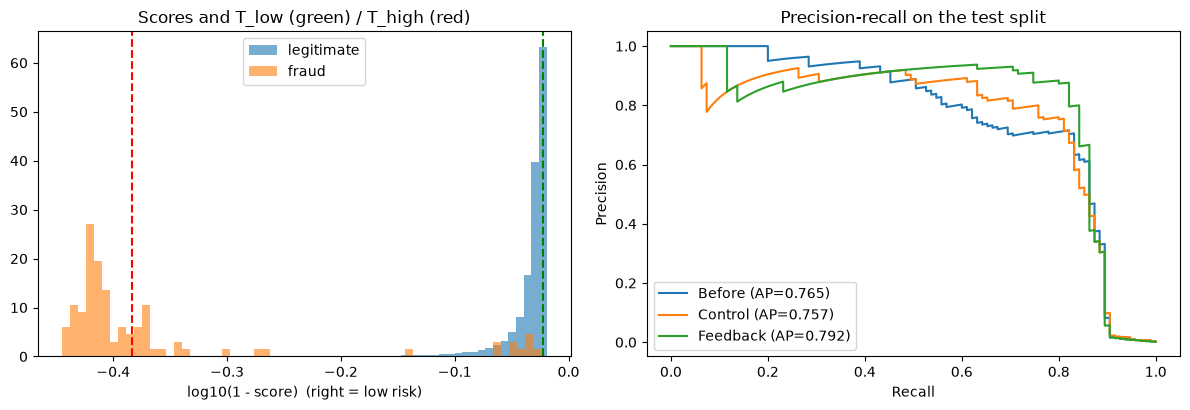

saved to results_pipeline : ['bench_feedback_stats.csv', 'bench_paired_differences.csv', 'bench_per_seed_metrics.csv', 'bench_summary_mean_std.csv', 'bench_summary_table.tex', 'bench_xai_faithfulness.csv', 'config.json', 'figA_comparison.png', 'figB_pr_roc.png', 'figC_banks.png', 'figD_convergence.png', 'figE_paired.png', 'figF_feedback.png', 'figG_xai.png', 'figH_zones_confusion.png', 'figI_email_replies.png', 'global_model_final.pt', 'metrics_before_after.csv', 'model_registry.json', 'paper_numbers.json', 'pipeline_figure.png', 'verification_log.csv', 'zones_base.csv', 'zones_before_feedback_base_.csv', 'zones_extra_rounds_cardholder_feedback.csv', 'zones_extra_rounds_no_feedback_control_.csv']


In [28]:
# ============ CELL 9: SAVE TABLES, FIGURES AND THE REGISTRY ============
import matplotlib.pyplot as plt
RES.to_csv(f"{OUT_DIR}/metrics_before_after.csv"); ZR_BASE.to_csv(f"{OUT_DIR}/zones_base.csv")
for k, v in ZR.items(): v.to_csv(f"{OUT_DIR}/zones_{re.sub('[^a-z]+', '_', k.lower())}.csv")
json.dump(REGISTRY, open(f"{OUT_DIR}/model_registry.json", "w"), indent=2)
torch.save(GM_FB.state_dict(), f"{OUT_DIR}/global_model_final.pt")
json.dump({k: v for k, v in globals().items() if k.isupper() and k != "GMAIL_USER" and isinstance(v, (int, float, str, bool, type(None)))},
          open(f"{OUT_DIR}/config.json", "w"), indent=2)

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
ax[0].hist(np.log10(1 - s_test[TEST[1] == 0] + 1e-9), bins=60, alpha=.6, label="legitimate", density=True)
ax[0].hist(np.log10(1 - s_test[TEST[1] == 1] + 1e-9), bins=60, alpha=.6, label="fraud", density=True)
for t, c in [(T_LOW, "g"), (T_HIGH, "r")]: ax[0].axvline(np.log10(1 - t + 1e-9), color=c, ls="--")
ax[0].set(xlabel="log10(1 - score)  (right = low risk)", title="Scores and T_low (green) / T_high (red)"); ax[0].legend()
for name, m in [("Before", GM), ("Control", GM_CT), ("Feedback", GM_FB)]:
    p_, r_, _ = precision_recall_curve(TEST[1], predict(m, TEST[0])); ax[1].plot(r_, p_, label=f"{name} (AP={average_precision_score(TEST[1], predict(m, TEST[0])):.3f})")
ax[1].set(xlabel="Recall", ylabel="Precision", title="Precision-recall on the test split"); ax[1].legend()
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/pipeline_figure.png", dpi=200); plt.show()
print("saved to", OUT_DIR, ":", sorted(os.listdir(OUT_DIR)))

## Cells 10-11: multi-seed benchmark and paper figures
Cell 10 repeats the **whole experiment for 5 seeds** (new stratified split, new scaler, new non-IID banks each time) and compares seven methods on the held-out test split: centralised HistGradientBoosting, centralised transformer, local-only banks, FedAvg transformer, FedAvg + supervised-contrastive loss, and the feedback / no-feedback pair.
With `QUICK = False` expect roughly 10-20 minutes per seed on a CPU (much less on a GPU). Cell 11 draws the figures and zips everything to `pipeline_results.zip`.
Send that zip back so the paper can be filled with **your own measured numbers**; no number in the paper should come from anywhere else.

In [30]:
# ============ CELL 10: MULTI-SEED BENCHMARK  (all methods, identical splits, matched training budget) ============
# Everything below is evaluated ONLY on each seed's held-out TEST split. Thresholds are chosen on the VALIDATION split.
import contextlib, io
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import balanced_accuracy_score, confusion_matrix, roc_curve

BENCH_SEEDS = [0, 1] if QUICK else [0, 1, 2, 3, 4]      # QUICK = smoke test; the real run uses 5 seeds
X_ORIG = X                                              # cells 5-8 use the global X: restored at the end of this cell
REGISTRY_BACKUP = list(REGISTRY)

def metrics_ext(y, s, thr):
    m = metrics(y, s, thr); pred = (s >= thr).astype(int)
    m["BalAcc"] = balanced_accuracy_score(y, pred)
    m["Specificity"] = float(((pred == 0) & (y == 0)).sum() / max(1, (y == 0).sum()))
    return m

def prepare(seed):
    """Fresh stratified split, scaler fitted on TRAIN only, non-IID banks, sequences - for one seed."""
    global X
    r = np.random.default_rng(seed)
    ids = np.arange(len(df))
    tr_, te_ = train_test_split(ids, test_size=0.20, stratify=y_all, random_state=seed)
    tr_, va_ = train_test_split(tr_, test_size=0.15, stratify=y_all[tr_], random_state=seed)
    tr_, po_ = train_test_split(tr_, test_size=0.20, stratify=y_all[tr_], random_state=seed)
    X = StandardScaler().fit(X_raw[tr_]).transform(X_raw).astype(np.float32)
    bk = partition(tr_, N_BANKS, DIRICHLET, r)
    return dict(tr=tr_, va=va_, pool=po_, te=te_, bank_ids=bk, BANKS=[make_seq(b) for b in bk],
                VAL=make_seq(va_), POOL=make_seq(po_), TEST=make_seq(te_), TRAIN=make_seq(tr_))

def fed_hist(gm, banks, rounds, supcon_w, tag, VALs):
    """Federated rounds one at a time, recording validation PR-AUC after every round (convergence curve)."""
    hist = []
    for r in range(rounds):
        with contextlib.redirect_stdout(io.StringIO()):
            gm = run_federation(gm, banks, 1, supcon_w, tag, start=r, verbose=False)
        hist.append(average_precision_score(VALs[1], predict(gm, VALs[0])))
    return gm, hist

def run_seed(seed):
    d = prepare(seed); np.random.seed(seed); torch.manual_seed(seed); r_ = np.random.default_rng(seed + 1000)
    BK, VAL_, POOL_, TEST_ = d["BANKS"], d["VAL"], d["POOL"], d["TEST"]; Yv, Yt = VAL_[1], TEST_[1]
    rows, SC = [], {}
    def log(name, sv, st, keep=True):
        thr = pick_threshold(Yv, sv); m = metrics_ext(Yt, st, thr); m.update(seed=seed, method=name); rows.append(m)
        if keep: SC[name] = (sv, st, thr)
        print(f"  seed {seed} | {name:<42} PR-AUC={m['PR-AUC']:.3f} F1={m['F1']:.3f} MCC={m['MCC']:.3f} alerts/100k={m['Alerts/100k']:.0f}")
    # 1. centralised gradient boosting (strong tabular baseline; sees all banks' raw data = privacy-violating upper reference)
    hgb = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.08, random_state=seed).fit(X[d["tr"]], y_all[d["tr"]])
    log("Centralized HGB", hgb.predict_proba(X[VAL_[2]])[:, 1], hgb.predict_proba(X[TEST_[2]])[:, 1])
    # 2. centralised transformer on the pooled training data (same number of epochs as the federation)
    m = SeqNet().to(DEV)
    for _ in range(ROUNDS): local_train(m, d["TRAIN"][0], d["TRAIN"][1], LOCAL_EPOCHS, 0.0)
    log("Centralized transformer", predict(m, VAL_[0]), predict(m, TEST_[0]))
    # 3. local-only: every bank trains alone (no sharing)
    for b, (S, y, _) in enumerate(BK):
        m = SeqNet().to(DEV)
        for _ in range(ROUNDS): local_train(m, S, y, LOCAL_EPOCHS, 0.0)
        log(f"Local-only (bank {b+1})", predict(m, VAL_[0]), predict(m, TEST_[0]), keep=False)
    # 4/5. federated averaging with secure aggregation: plain, and with the supervised-contrastive loss
    g_plain, h_plain = fed_hist(SeqNet().to(DEV), BK, ROUNDS, 0.0, f"s{seed}-plain", VAL_)
    log("FedAvg transformer", predict(g_plain, VAL_[0]), predict(g_plain, TEST_[0]))
    g_sc, h_sc = fed_hist(SeqNet().to(DEV), BK, ROUNDS, SUPCON_W, f"s{seed}-supcon", VAL_)
    sv, st = predict(g_sc, VAL_[0]), predict(g_sc, TEST_[0]); log("FedAvg + SupCon", sv, st)
    # 6. three-zone decision (T_low / T_high chosen on validation) for the deployed model
    tl, th = thresholds(Yv, sv); zr = zone_report(Yt, st, tl, th)
    # 7. cardholder feedback (simulated user: responds with prob USER_RESPONSE, correct with prob USER_ACCURACY) vs control
    sp = predict(g_sc, POOL_[0]); flagged = np.where(zones(sp, tl, th) != "auto-approve")[0]; labs = {}
    for j in flagged:
        if r_.random() < USER_RESPONSE:
            t_ = int(POOL_[1][j]); labs[int(j)] = t_ if r_.random() < USER_ACCURACY else 1 - t_
    ids_ = np.array(sorted(labs), dtype=int); lab = np.array([labs[i] for i in ids_], dtype=int)
    own = r_.integers(0, N_BANKS, len(ids_))
    fb_sets = [(np.concatenate([BK[b][0], POOL_[0][ids_[own == b]]]), np.concatenate([BK[b][1], lab[own == b]])) for b in range(N_BANKS)]
    with contextlib.redirect_stdout(io.StringIO()):
        g_fb = run_federation(copy.deepcopy(g_sc), fb_sets, FB_ROUNDS, SUPCON_W, f"s{seed}-fb")
        g_ct = run_federation(copy.deepcopy(g_sc), BK, FB_ROUNDS, SUPCON_W, f"s{seed}-ctl")
    log("FedAvg + SupCon, extra rounds (control)", predict(g_ct, VAL_[0]), predict(g_ct, TEST_[0]))
    log("FedAvg + SupCon + cardholder feedback", predict(g_fb, VAL_[0]), predict(g_fb, TEST_[0]))
    fbs = dict(seed=seed, flagged=len(flagged), labels=len(ids_), wrong=int((lab != POOL_[1][ids_]).sum()) if len(ids_) else 0,
               fraud_labels=int(lab.sum()), pool_n=len(POOL_[1]), pool_frauds=int(POOL_[1].sum()))
    # 8. explanation faithfulness on blocked true frauds (gradient x input vs random deletion)
    hit = np.where((Yt == 1) & (st >= th))[0][:1000]
    xai = dict(seed=seed, n=len(hit), top3=np.nan, rand3=np.nan)
    if len(hit): xai["top3"], xai["rand3"] = faithfulness(g_sc, TEST_[0][hit])
    info = dict(zr=zr, tl=tl, th=th, fb=fbs, xai=xai, h_plain=h_plain, h_sc=h_sc, scores=SC, y_test=Yt,
                bank_n=[len(b[1]) for b in BK], bank_f=[int(b[1].sum()) for b in BK],
                test_n=len(Yt), test_f=int(Yt.sum()))
    return rows, info

t0 = time.time(); ALL, INFO = [], {}
try:
    for sd in BENCH_SEEDS:
        print(f"\n===== SEED {sd}  ({time.time()-t0:.0f}s elapsed) =====")
        r_rows, INFO[sd] = run_seed(sd); ALL += r_rows
finally:
    X = X_ORIG; REGISTRY[:] = REGISTRY_BACKUP            # restore the state used by cells 5-8
R = pd.DataFrame(ALL)
R["method"] = R["method"].str.replace(r"Local-only \(bank \d+\)", "Local-only (mean of banks)", regex=True)
R = R.groupby(["seed", "method"], as_index=False).mean(numeric_only=True)
ORDER = ["Centralized HGB", "Centralized transformer", "Local-only (mean of banks)", "FedAvg transformer", "FedAvg + SupCon",
         "FedAvg + SupCon, extra rounds (control)", "FedAvg + SupCon + cardholder feedback"]
METS = ["PR-AUC", "ROC-AUC", "Precision", "Recall", "F1", "MCC", "BalAcc", "Specificity", "Alerts/100k"]
g = R.groupby("method")[METS]; MEAN, STD = g.mean().loc[ORDER], g.std(ddof=1).loc[ORDER]
SUMMARY = MEAN.copy().astype(object)
for c in METS: SUMMARY[c] = [f"{a:.0f} ± {b:.0f}" if c == "Alerts/100k" else f"{a:.3f} ± {b:.3f}" for a, b in zip(MEAN[c], STD[c])]
print(f"\nTABLE: mean ± std over {len(BENCH_SEEDS)} seeds, TEST split only (about {INFO[BENCH_SEEDS[0]]['test_f']} frauds per seed)")
display(SUMMARY)

def paired(a, b, metric="PR-AUC"):
    A = R[R.method == a].set_index("seed")[metric]; B = R[R.method == b].set_index("seed")[metric]; dlt = (A - B).dropna()
    n = len(dlt); return dict(comparison=f"{a}  minus  {b}", metric=metric, mean_diff=dlt.mean(), std_diff=dlt.std(ddof=1) if n > 1 else np.nan,
                              seeds_a_better=int((dlt > 0).sum()), n_seeds=n, min_two_sided_sign_test_p=min(1.0, 2 * 0.5 ** n))
PAIRS = [("FedAvg transformer", "Local-only (mean of banks)"), ("FedAvg transformer", "Centralized transformer"),
         ("FedAvg transformer", "Centralized HGB"), ("FedAvg + SupCon", "FedAvg transformer"),
         ("FedAvg + SupCon + cardholder feedback", "FedAvg + SupCon, extra rounds (control)")]
PAIRED = pd.DataFrame([paired(a, b, m) for a, b in PAIRS for m in ("PR-AUC", "F1")])
print("\nPAIRED DIFFERENCES (same seed, same split). With n seeds the smallest attainable two-sided sign-test p is 2/2^n: do not claim significance with n=5.")
display(PAIRED.style.format({"mean_diff": "{:+.3f}", "std_diff": "{:.3f}", "min_two_sided_sign_test_p": "{:.4f}"}))
FB = pd.DataFrame([INFO[s]["fb"] for s in BENCH_SEEDS]).set_index("seed"); XAI = pd.DataFrame([INFO[s]["xai"] for s in BENCH_SEEDS]).set_index("seed")
print("\nSimulated cardholder feedback statistics per seed (labels = answers received; wrong = answers that disagree with the dataset label)"); display(FB)
print("Deletion (faithfulness) test per seed: mean fall of the fraud score after removing the top-3 attributed features vs 3 random features"); display(XAI)
print("NOTE: the feedback arm also receives extra labelled transactions, so any gain over the control is not only 'more rounds'; it is label information.")

os.makedirs(OUT_DIR, exist_ok=True)
R.to_csv(f"{OUT_DIR}/bench_per_seed_metrics.csv", index=False); SUMMARY.to_csv(f"{OUT_DIR}/bench_summary_mean_std.csv")
PAIRED.to_csv(f"{OUT_DIR}/bench_paired_differences.csv", index=False); FB.to_csv(f"{OUT_DIR}/bench_feedback_stats.csv"); XAI.to_csv(f"{OUT_DIR}/bench_xai_faithfulness.csv")
open(f"{OUT_DIR}/bench_summary_table.tex", "w").write(SUMMARY.to_latex(escape=True))
print(f"\nbenchmark finished in {(time.time()-t0)/60:.1f} min; tables saved to {OUT_DIR}/")


===== SEED 0  (0s elapsed) =====
  seed 0 | Centralized HGB                            PR-AUC=0.671 F1=0.709 MCC=0.711 alerts/100k=141
  seed 0 | Centralized transformer                    PR-AUC=0.793 F1=0.833 MCC=0.834 alerts/100k=150
  seed 0 | Local-only (bank 1)                        PR-AUC=0.755 F1=0.804 MCC=0.806 alerts/100k=148
  seed 0 | Local-only (bank 2)                        PR-AUC=0.776 F1=0.807 MCC=0.809 alerts/100k=143
  seed 0 | Local-only (bank 3)                        PR-AUC=0.268 F1=0.384 MCC=0.384 alerts/100k=145
  seed 0 | FedAvg transformer                         PR-AUC=0.777 F1=0.804 MCC=0.804 alerts/100k=166
  seed 0 | FedAvg + SupCon                            PR-AUC=0.741 F1=0.794 MCC=0.793 alerts/100k=166
  seed 0 | FedAvg + SupCon, extra rounds (control)    PR-AUC=0.777 F1=0.792 MCC=0.792 alerts/100k=180
  seed 0 | FedAvg + SupCon + cardholder feedback      PR-AUC=0.778 F1=0.827 MCC=0.828 alerts/100k=148

===== SEED 1  (109s elapsed) =====
  seed 1 | C

,PR-AUC,ROC-AUC,Precision,Recall,F1,MCC,BalAcc,Specificity,Alerts/100k
method,,,,,,,,,
Centralized HGB,0.511 ± 0.226,0.787 ± 0.094,0.677 ± 0.139,0.616 ± 0.052,0.644 ± 0.092,0.644 ± 0.094,0.808 ± 0.026,0.999 ± 0.000,154 ± 19
Centralized transformer,0.741 ± 0.073,0.970 ± 0.022,0.878 ± 0.006,0.758 ± 0.045,0.813 ± 0.028,0.815 ± 0.027,0.879 ± 0.022,1.000 ± 0.000,145 ± 7
Local-only (mean of banks),0.532 ± 0.095,0.874 ± 0.135,0.651 ± 0.092,0.542 ± 0.112,0.591 ± 0.104,0.593 ± 0.104,0.770 ± 0.057,0.998 ± 0.002,301 ± 220
FedAvg transformer,0.745 ± 0.044,0.960 ± 0.018,0.835 ± 0.037,0.758 ± 0.060,0.793 ± 0.016,0.794 ± 0.014,0.879 ± 0.030,1.000 ± 0.000,152 ± 19
FedAvg + SupCon,0.705 ± 0.051,0.966 ± 0.019,0.787 ± 0.015,0.705 ± 0.119,0.742 ± 0.073,0.744 ± 0.070,0.852 ± 0.060,1.000 ± 0.000,150 ± 22
"FedAvg + SupCon, extra rounds (control)",0.732 ± 0.064,0.965 ± 0.021,0.791 ± 0.038,0.742 ± 0.112,0.762 ± 0.042,0.764 ± 0.039,0.871 ± 0.056,1.000 ± 0.000,158 ± 31
FedAvg + SupCon + cardholder feedback,0.691 ± 0.122,0.965 ± 0.019,0.818 ± 0.090,0.632 ± 0.208,0.708 ± 0.168,0.716 ± 0.159,0.816 ± 0.104,1.000 ± 0.000,128 ± 29



PAIRED DIFFERENCES (same seed, same split). With n seeds the smallest attainable two-sided sign-test p is 2/2^n: do not claim significance with n=5.


,comparison,metric,mean_diff,std_diff,seeds_a_better,n_seeds,min_two_sided_sign_test_p
0,FedAvg transformer minus Local-only (mean of banks),PR-AUC,+0.213,0.051,2,2,0.5000
1,FedAvg transformer minus Local-only (mean of banks),F1,+0.202,0.088,2,2,0.5000
2,FedAvg transformer minus Centralized transformer,PR-AUC,+0.004,0.028,1,2,0.5000
3,FedAvg transformer minus Centralized transformer,F1,-0.020,0.012,0,2,0.5000
4,FedAvg transformer minus Centralized HGB,PR-AUC,+0.234,0.182,2,2,0.5000
5,FedAvg transformer minus Centralized HGB,F1,+0.149,0.076,2,2,0.5000
6,FedAvg + SupCon minus FedAvg transformer,PR-AUC,-0.041,0.006,0,2,0.5000
7,FedAvg + SupCon minus FedAvg transformer,F1,-0.051,0.057,0,2,0.5000
8,"FedAvg + SupCon + cardholder feedback minus FedAvg + SupCon, extra rounds (control)",PR-AUC,-0.041,0.059,1,2,0.5000
9,"FedAvg + SupCon + cardholder feedback minus FedAvg + SupCon, extra rounds (control)",F1,-0.054,0.126,1,2,0.5000



Simulated cardholder feedback statistics per seed (labels = answers received; wrong = answers that disagree with the dataset label)


,flagged,labels,wrong,fraud_labels,pool_n,pool_frauds
seed,,,,,,
0,13664,8208,396,425,38587,64
1,2468,1494,69,95,38587,64


Deletion (faithfulness) test per seed: mean fall of the fraud score after removing the top-3 attributed features vs 3 random features


,n,top3,rand3
seed,,,
0,75,0.056363,0.009979
1,59,0.125056,0.012465


NOTE: the feedback arm also receives extra labelled transactions, so any gain over the control is not only 'more rounds'; it is label information.

benchmark finished in 3.6 min; tables saved to results_pipeline/


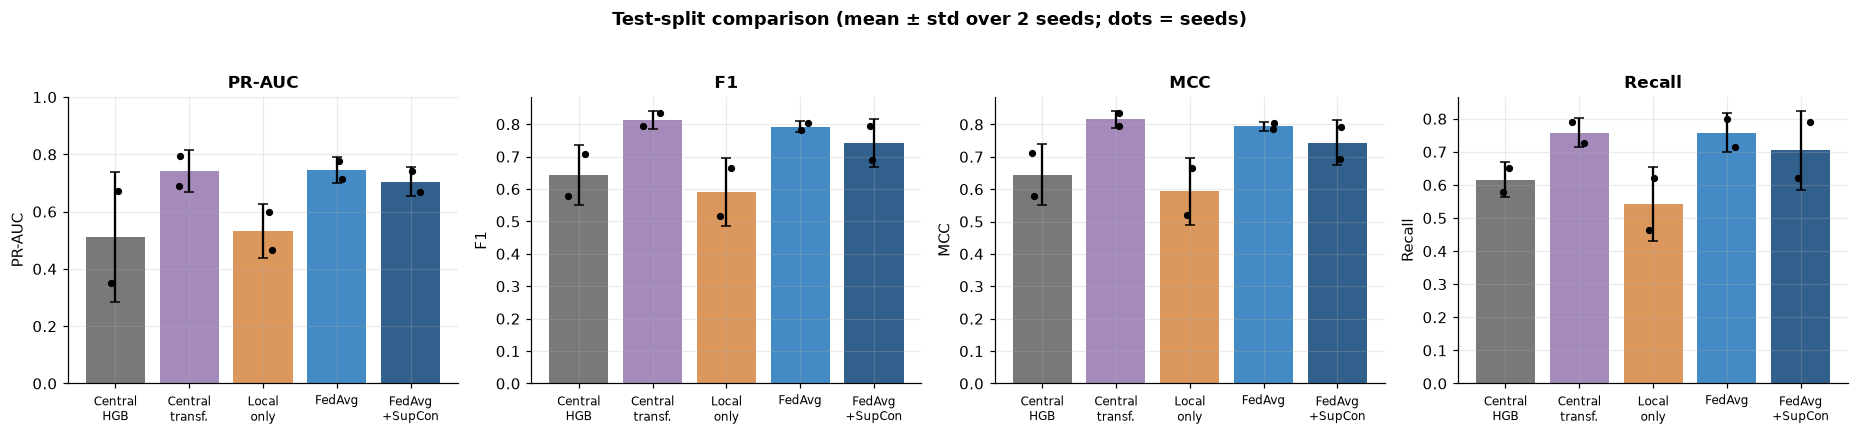

findfont: Font family ['cmmi10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmsy10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmr10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmtt10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmti10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmb10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmss10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmex10'] not found. Falling back to DejaVu Sans.


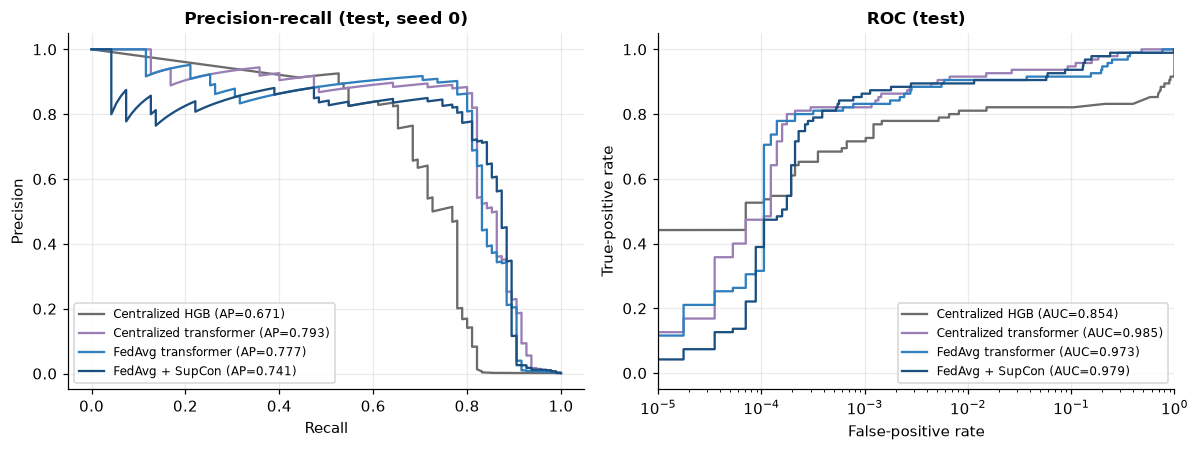

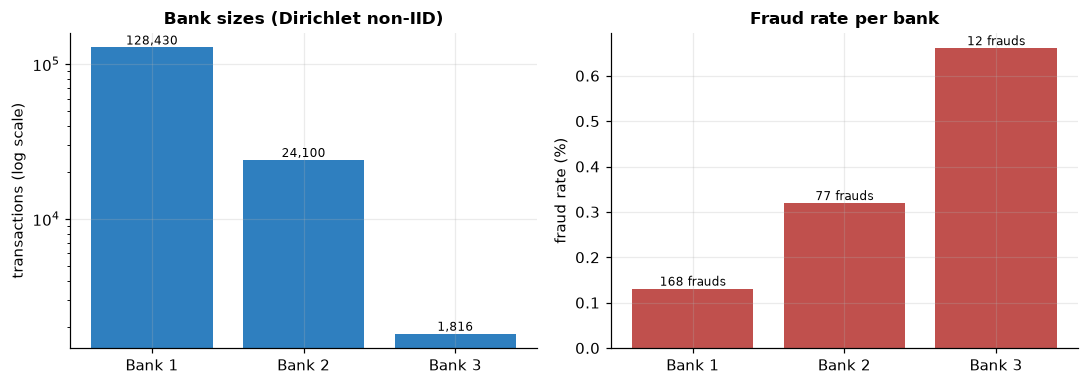

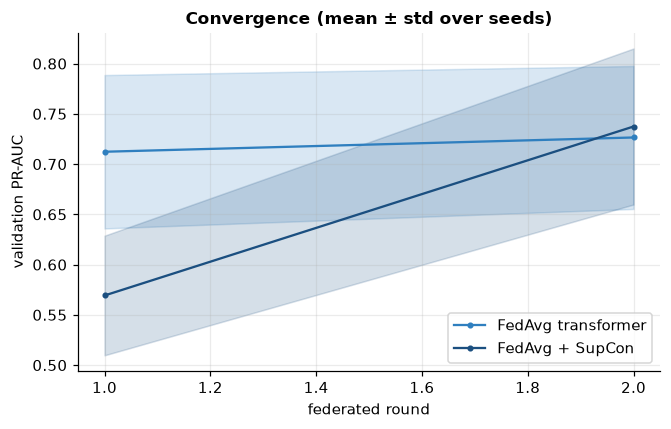

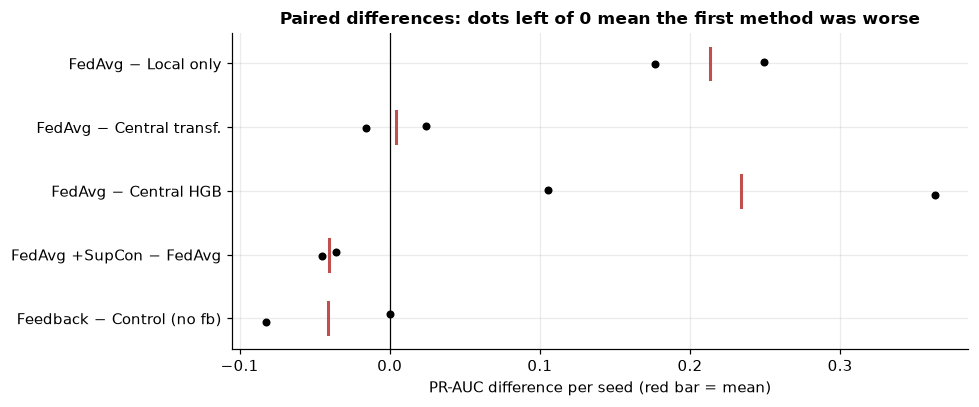

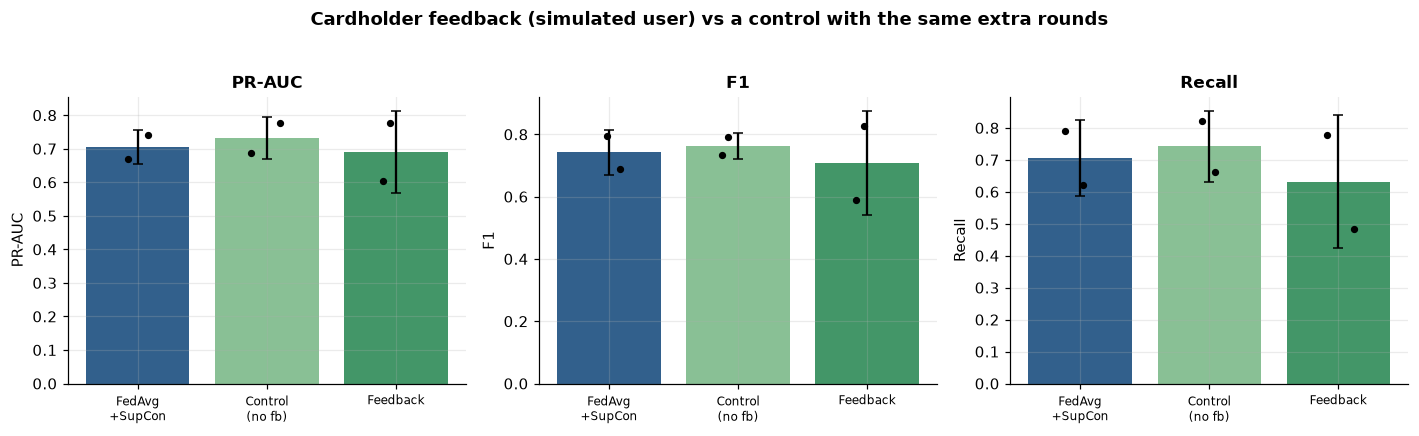

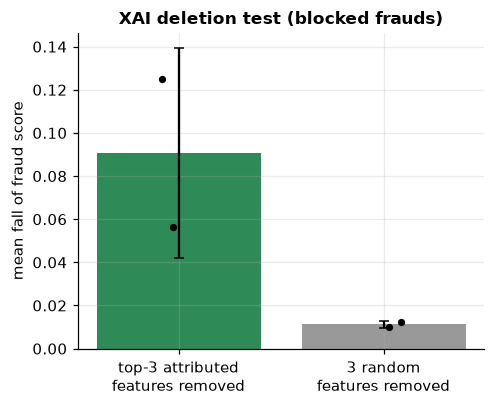

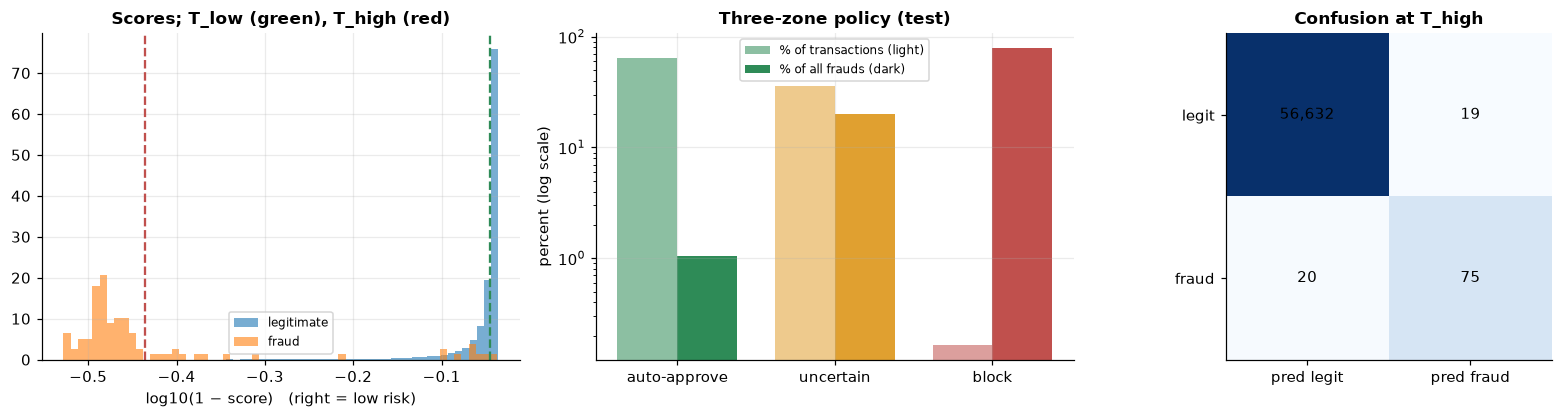

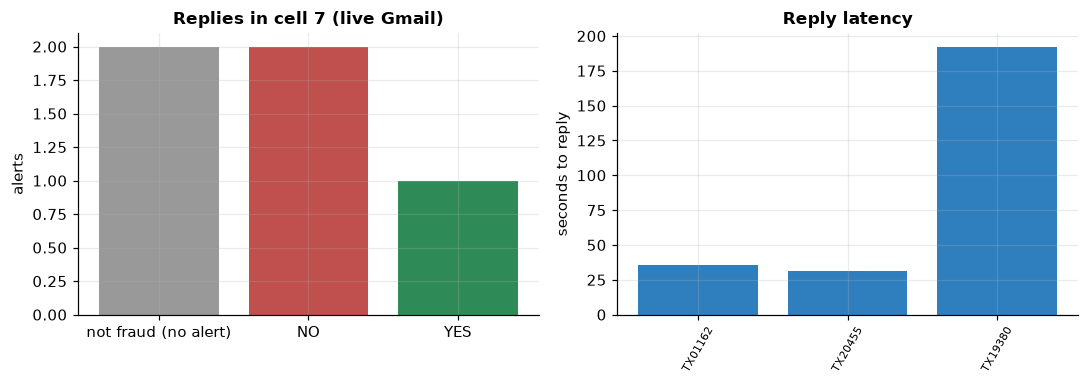

saved figures + tables in results_pipeline and zipped to pipeline_results.zip  (send this zip back so the paper can be filled with YOUR real numbers)


In [33]:
# ============ CELL 11: FIGURES FOR THE PAPER (all saved as PNG, 200 dpi) ============
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25,
                     "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold"})
COL = {"Centralized HGB": "#6b6b6b", "Centralized transformer": "#9a7fb5", "Local-only (mean of banks)": "#d98c4b",
       "FedAvg transformer": "#2f7fbf", "FedAvg + SupCon": "#1b4f80", "FedAvg + SupCon, extra rounds (control)": "#7cb98a",
       "FedAvg + SupCon + cardholder feedback": "#2e8b57"}
SHORT = {"Centralized HGB": "Central\nHGB", "Centralized transformer": "Central\ntransf.", "Local-only (mean of banks)": "Local\nonly",
         "FedAvg transformer": "FedAvg", "FedAvg + SupCon": "FedAvg\n+SupCon", "FedAvg + SupCon, extra rounds (control)": "Control\n(no fb)",
         "FedAvg + SupCon + cardholder feedback": "Feedback"}
SEEDS_ = BENCH_SEEDS; S0 = SEEDS_[0]; jit = np.random.default_rng(0)
def bars(ax, metric, methods, title=None):
    for i, mth in enumerate(methods):
        v = R[R.method == mth].sort_values("seed")[metric].values
        ax.bar(i, v.mean(), yerr=v.std(ddof=1) if len(v) > 1 else 0, color=COL[mth], capsize=3, alpha=.9)
        ax.scatter(i + jit.uniform(-.14, .14, len(v)), v, s=14, color="k", zorder=3)
    ax.set_xticks(range(len(methods))); ax.set_xticklabels([SHORT[m] for m in methods], fontsize=8); ax.set_ylabel(metric); ax.set_title(title or metric)

# Fig A: main comparison, four metrics
fig, ax = plt.subplots(1, 4, figsize=(17, 3.8))
for a, m_ in zip(ax, ["PR-AUC", "F1", "MCC", "Recall"]): bars(a, m_, ORDER[:5])
ax[0].set_ylim(0, 1); fig.suptitle(f"Test-split comparison (mean ± std over {len(SEEDS_)} seeds; dots = seeds)", y=1.03, fontweight="bold")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/figA_comparison.png", dpi=200, bbox_inches="tight"); plt.show()

# Fig B: PR and ROC curves (seed S0)
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2)); sc0 = INFO[S0]["scores"]; y0 = INFO[S0]["y_test"]
for name in ["Centralized HGB", "Centralized transformer", "FedAvg transformer", "FedAvg + SupCon"]:
    st_ = sc0[name][1]; p_, r_, _ = precision_recall_curve(y0, st_); f_, t_, _ = roc_curve(y0, st_)
    ax[0].plot(r_, p_, color=COL[name], label=f"{name} (AP={average_precision_score(y0, st_):.3f})")
    ax[1].plot(f_, t_, color=COL[name], label=f"{name} (AUC={roc_auc_score(y0, st_):.3f})")
ax[0].set(xlabel="Recall", ylabel="Precision", title=f"Precision-recall (test, seed {S0})"); ax[0].legend(fontsize=8)
ax[1].set(xlabel="False-positive rate", ylabel="True-positive rate", title="ROC (test)", xscale="log", xlim=(1e-5, 1)); ax[1].legend(fontsize=8, loc="lower right")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/figB_pr_roc.png", dpi=200); plt.show()

# Fig C: simulated banks (non-IID)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6)); bn, bf = INFO[S0]["bank_n"], INFO[S0]["bank_f"]; lab_ = [f"Bank {i+1}" for i in range(len(bn))]
ax[0].bar(lab_, bn, color="#2f7fbf"); ax[0].set_yscale("log"); ax[0].set(ylabel="transactions (log scale)", title="Bank sizes (Dirichlet non-IID)")
for i, v in enumerate(bn): ax[0].text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=8)
ax[1].bar(lab_, [f / n * 100 for f, n in zip(bf, bn)], color="#c0504d"); ax[1].set(ylabel="fraud rate (%)", title="Fraud rate per bank")
for i, (f, n) in enumerate(zip(bf, bn)): ax[1].text(i, f / n * 100, f"{f} frauds", ha="center", va="bottom", fontsize=8)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/figC_banks.png", dpi=200); plt.show()

# Fig D: convergence of the federation (validation PR-AUC per round)
fig, ax = plt.subplots(figsize=(6.2, 4))
for key, name in [("h_plain", "FedAvg transformer"), ("h_sc", "FedAvg + SupCon")]:
    H = np.array([INFO[s][key] for s in SEEDS_]); x = np.arange(1, H.shape[1] + 1)
    ax.plot(x, H.mean(0), color=COL[name], marker="o", ms=3, label=name)
    if len(H) > 1: ax.fill_between(x, H.mean(0) - H.std(0, ddof=1), H.mean(0) + H.std(0, ddof=1), color=COL[name], alpha=.18)
ax.set(xlabel="federated round", ylabel="validation PR-AUC", title="Convergence (mean ± std over seeds)"); ax.legend()
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/figD_convergence.png", dpi=200); plt.show()

# Fig E: paired differences per seed
fig, ax = plt.subplots(figsize=(9, 3.8)); comp = [(a, b) for a, b in PAIRS]; ylabs = []
for i, (a, b) in enumerate(comp):
    A = R[R.method == a].set_index("seed")["PR-AUC"]; B = R[R.method == b].set_index("seed")["PR-AUC"]; dd = (A - B).values
    ax.scatter(dd, np.full(len(dd), i) + jit.uniform(-.08, .08, len(dd)), color="k", s=18, zorder=3); ax.plot([dd.mean()] * 2, [i - .25, i + .25], color="#c0504d", lw=2)
    ylabs.append(f"{SHORT[a].replace(chr(10), ' ')} − {SHORT[b].replace(chr(10), ' ')}")
ax.axvline(0, color="k", lw=.8); ax.set_yticks(range(len(comp))); ax.set_yticklabels(ylabs); ax.invert_yaxis()
ax.set(xlabel="PR-AUC difference per seed (red bar = mean)", title="Paired differences: dots left of 0 mean the first method was worse")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/figE_paired.png", dpi=200); plt.show()

# Fig F: feedback vs control
fig, ax = plt.subplots(1, 3, figsize=(13, 3.8)); trio = ["FedAvg + SupCon", "FedAvg + SupCon, extra rounds (control)", "FedAvg + SupCon + cardholder feedback"]
for a, m_ in zip(ax, ["PR-AUC", "F1", "Recall"]): bars(a, m_, trio)
fig.suptitle("Cardholder feedback (simulated user) vs a control with the same extra rounds", y=1.03, fontweight="bold")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/figF_feedback.png", dpi=200, bbox_inches="tight"); plt.show()

# Fig G: explanation faithfulness
fig, ax = plt.subplots(figsize=(4.6, 3.8)); xv = XAI.dropna()
for i, (c_, col) in enumerate([("top3", "#2e8b57"), ("rand3", "#999999")]):
    ax.bar(i, xv[c_].mean(), yerr=xv[c_].std(ddof=1) if len(xv) > 1 else 0, color=col, capsize=3); ax.scatter(i + jit.uniform(-.1, .1, len(xv)), xv[c_], color="k", s=14, zorder=3)
ax.set_xticks([0, 1]); ax.set_xticklabels(["top-3 attributed\nfeatures removed", "3 random\nfeatures removed"]); ax.set_ylabel("mean fall of fraud score")
ax.set_title("XAI deletion test (blocked frauds)"); plt.tight_layout(); plt.savefig(f"{OUT_DIR}/figG_xai.png", dpi=200); plt.show()

# Fig H: three-zone decision (seed S0) and confusion matrix at T_high
zr = INFO[S0]["zr"]; sv_, st_, thr_ = INFO[S0]["scores"]["FedAvg + SupCon"]; tl, th = INFO[S0]["tl"], INFO[S0]["th"]
fig, ax = plt.subplots(1, 3, figsize=(15, 3.9)); zc = {"auto-approve": "#2e8b57", "uncertain": "#e0a030", "block": "#c0504d"}
ax[0].hist(np.log10(1 - st_[y0 == 0] + 1e-9), bins=60, alpha=.6, density=True, label="legitimate"); ax[0].hist(np.log10(1 - st_[y0 == 1] + 1e-9), bins=60, alpha=.6, density=True, label="fraud")
for t_, c_ in [(tl, "#2e8b57"), (th, "#c0504d")]: ax[0].axvline(np.log10(1 - t_ + 1e-9), color=c_, ls="--")
ax[0].set(xlabel="log10(1 − score)   (right = low risk)", title="Scores; T_low (green), T_high (red)"); ax[0].legend(fontsize=8)
w = .38; xs = np.arange(3)
ax[1].bar(xs - w / 2, np.maximum(zr["transactions/100k"] / 1e3, 1e-3), w, color=[zc[z] for z in zr.index], alpha=.55, label="% of transactions (light)")
ax[1].bar(xs + w / 2, np.maximum(zr["share of all frauds"] * 100, 1e-3), w, color=[zc[z] for z in zr.index], label="% of all frauds (dark)")
ax[1].set_xticks(xs); ax[1].set_xticklabels(zr.index); ax[1].set_yscale("log"); ax[1].set_ylabel("percent (log scale)"); ax[1].legend(fontsize=8); ax[1].set_title("Three-zone policy (test)")
cm = confusion_matrix(y0, (st_ >= th).astype(int)); ax[2].imshow(np.log10(cm + 1), cmap="Blues")
for (i, j), v in np.ndenumerate(cm): ax[2].text(j, i, f"{v:,}", ha="center", va="center", color="k")
ax[2].set_xticks([0, 1]); ax[2].set_yticks([0, 1]); ax[2].set_xticklabels(["pred legit", "pred fraud"]); ax[2].set_yticklabels(["legit", "fraud"]); ax[2].grid(False); ax[2].set_title("Confusion at T_high")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/figH_zones_confusion.png", dpi=200); plt.show()

# Fig I: cardholder messages: what the e-mail loop produced (cell 7 log, dry run or live)
if "LIVE_LOG" in globals() and len(LIVE_LOG):
    fig, ax = plt.subplots(1, 2, figsize=(10, 3.6)); vc = LIVE_LOG["verdict"].value_counts()
    ax[0].bar(vc.index, vc.values, color=["#2e8b57" if v == "YES" else "#c0504d" if v == "NO" else "#999" for v in vc.index]); ax[0].set(ylabel="alerts", title=f"Replies in cell 7 ({'live Gmail' if LIVE_EMAIL else 'DRY RUN'})")
    rs = LIVE_LOG.dropna(subset=["reply_seconds"]); ax[1].bar(range(len(rs)), rs["reply_seconds"], color="#2f7fbf"); ax[1].set_xticks(range(len(rs))); ax[1].set_xticklabels(rs["tx"], rotation=60, fontsize=7); ax[1].set(ylabel="seconds to reply", title="Reply latency")
    plt.tight_layout(); plt.savefig(f"{OUT_DIR}/figI_email_replies.png", dpi=200); plt.show()

json.dump({"seeds": SEEDS_, "summary_mean": MEAN.round(4).to_dict(), "summary_std": STD.round(4).to_dict(),
           "paired": PAIRED.round(4).to_dict("records"), "feedback_stats": FB.to_dict("index"), "xai": XAI.round(4).to_dict("index"),
           "bank_sizes_seed0": INFO[S0]["bank_n"], "bank_frauds_seed0": INFO[S0]["bank_f"], "zones_seed0": INFO[S0]["zr"].round(4).to_dict("index")},
          open(f"{OUT_DIR}/paper_numbers.json", "w"), indent=2, default=float)
import shutil; shutil.make_archive("pipeline_results", "zip", OUT_DIR)
print("saved figures + tables in", OUT_DIR, "and zipped to pipeline_results.zip  (send this zip back so the paper can be filled with YOUR real numbers)")

## Cell 12: extensions for the journal version
Run after cell 11. It (1) uses 10 seeds with paired tests and bootstrap confidence intervals, (2) tests whether the cardholder-feedback gain survives data-matched controls (same number of TRUE labels on random rows; an oracle with all flagged rows) and how it changes with the response rate and answer accuracy, and (3) gives the hold-load / safety trade-off with a ceiling on the share of customers who are asked. Set `QUICK=False` first; the full run takes a long time on a CPU (reduce `EXT_SEEDS` if needed).

seed 0 done (96s)
seed 1 done (186s)

TABLE E1: mean and sd over 2 seeds (TEST split only)


PR-AUC            F1         \
                                                mean    std   mean    std   
setting                                                                     
A. control: extra rounds, no new labels        0.733  0.025  0.743  0.005   
B. cardholder feedback (resp=0.6, acc=0.95)    0.678  0.085  0.719  0.140   
C. random pool rows, TRUE labels (same count)  0.728  0.053  0.745  0.025   
D. all flagged rows, TRUE labels (oracle)      0.752  0.061  0.785  0.047   
FedAvg (no SupCon)                             0.727  0.066  0.793  0.032   
FedAvg + SupCon (base)                         0.717  0.070  0.748  0.061   

                                                 MCC        Precision         \
                                                mean    std      mean    std   
setting                                                                        
A. control: extra rounds, no new labels        0.748  0.000     0.838  0.047   
B. cardholder feedback (resp=0.6, acc=0.95)    0.722  0.140     0.793  0.135   
C. random pool rows, TRUE labels (same count)  0.751  0.022     0.852  0.008   
D. all flagged rows, TRUE labels (oracle)      0.789  0.041     0.873  0.018   
FedAvg (no SupCon)                             0.795  0.031     0.859  0.015   
FedAvg + SupCon (base)                         0.755  0.052     0.851  0.034   

                                              Recall        Alerts/100k  \
                                                mean    std        mean   
setting                                                                   
A. control: extra rounds, no new labels        0.668  0.037     133.930   
B. cardholder feedback (resp=0.6, acc=0.95)    0.658  0.141     138.336   
C. random pool rows, TRUE labels (same count)  0.663  0.045     130.406   
D. all flagged rows, TRUE labels (oracle)      0.716  0.089     137.455   
FedAvg (no SupCon)                             0.737  0.045     143.622   
FedAvg + SupCon (base)                         0.674  0.119     133.049   

                                                       
                                                  std  
setting                                                
A. control: extra rounds, no new labels        14.953  
B. cardholder feedback (resp=0.6, acc=0.95)     6.230  
C. random pool rows, TRUE labels (same count)   9.969  
D. all flagged rows, TRUE labels (oracle)      19.937  
FedAvg (no SupCon)                              6.230  
FedAvg + SupCon (base)                         28.660


TABLE E2: paired tests (same seed = same split). Read 'mean_diff' with its bootstrap CI; with <10 seeds treat p-values as indicative.


,a,b,metric,n,mean_diff,ci95_lo,ci95_hi,t_test_p,wilcoxon_p,a_better_in
0,FedAvg + SupCon (base),FedAvg (no SupCon),PR-AUC,2,-0.0102,-0.0128,-0.0077,0.1563,0.5,0
1,FedAvg + SupCon (base),FedAvg (no SupCon),F1,2,-0.0451,-0.0657,-0.0244,0.2734,0.5,0
2,"B. cardholder feedback (resp=0.6, acc=0.95)","A. control: extra rounds, no new labels",PR-AUC,2,-0.0550,-0.0971,-0.0129,0.4159,0.5,0
3,"B. cardholder feedback (resp=0.6, acc=0.95)","A. control: extra rounds, no new labels",F1,2,-0.0235,-0.1195,0.0724,0.8468,1.0,1
4,"B. cardholder feedback (resp=0.6, acc=0.95)","C. random pool rows, TRUE labels (same count)",PR-AUC,2,-0.0508,-0.0735,-0.0280,0.2682,0.5,0
5,"B. cardholder feedback (resp=0.6, acc=0.95)","C. random pool rows, TRUE labels (same count)",F1,2,-0.0261,-0.1074,0.0552,0.8022,1.0,1
6,"D. all flagged rows, TRUE labels (oracle)","B. cardholder feedback (resp=0.6, acc=0.95)",PR-AUC,2,0.0747,0.0578,0.0915,0.1414,0.5,2
7,"D. all flagged rows, TRUE labels (oracle)","B. cardholder feedback (resp=0.6, acc=0.95)",F1,2,0.0656,-0.0005,0.1316,0.5024,1.0,1


How to read E2:  B vs A = does feedback beat extra rounds?   B vs C = does the cardholder channel beat simply having the same number of true labels?
                 D vs B = how much is lost to non-response and wrong answers.

TABLE E3: PR-AUC gain of cardholder feedback over the control, by response rate (rho) and answer accuracy (acc)


,,mean,std,count
rho,acc,,,
0.6,0.95,-0.055,0.0595,2



TABLE E4: miss budget eta vs hold load (mean over 2 seeds). cap=NaN: no ceiling; cap=0.05: hold share limited to 5% of transactions


hold_load_pct  auto_missed_frauds  recall_block  \
eta  cap                                                     
0.00 0.05         5.0629                10.5        0.6737   
     NaN         55.1219                 5.0        0.6737   
0.01 0.05         5.0629                10.5        0.6737   
     NaN         55.1219                 5.0        0.6737   
0.02 0.05         5.0629                10.5        0.6737   
     NaN         30.1316                 7.5        0.6737   
0.05 0.05         4.7898                10.5        0.6737   
     NaN         24.5744                 7.5        0.6737   
0.10 0.05         2.4495                14.0        0.6737   
     NaN          2.4495                14.0        0.6737   
0.20 0.05         0.5137                16.0        0.6737   
     NaN          0.5137                16.0        0.6737   

           recall_block_or_hold  block_precision  
eta  cap                                          
0.00 0.05                0.8895           0.8513  
     NaN                 0.9474           0.8513  
0.01 0.05                0.8895           0.8513  
     NaN                 0.9474           0.8513  
0.02 0.05                0.8895           0.8513  
     NaN                 0.9211           0.8513  
0.05 0.05                0.8895           0.8513  
     NaN                 0.9211           0.8513  
0.10 0.05                0.8526           0.8513  
     NaN                 0.8526           0.8513  
0.20 0.05                0.8316           0.8513  
     NaN                 0.8316           0.8513

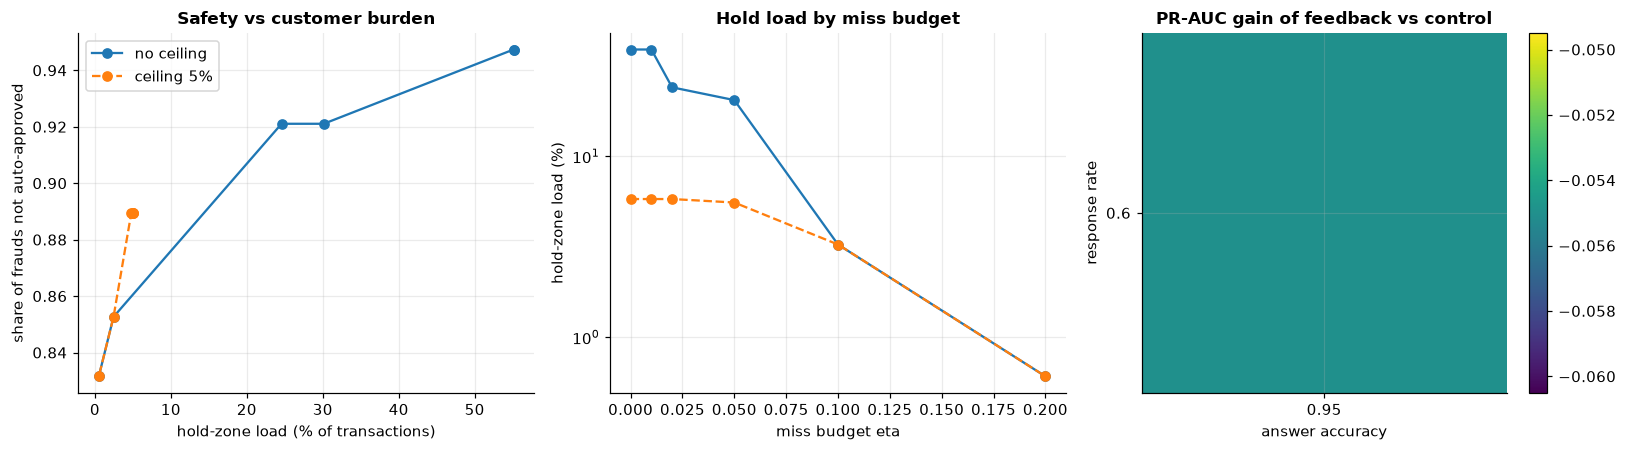


extensions finished in 3.2 min; tables/figure saved to results_pipeline/ (ext_*.csv, figJ_extensions.png)
re-zipped everything (including the extension tables) to pipeline_results.zip - send this zip back to update the paper with your real numbers


In [36]:
# ============ CELL 12: EXTENSIONS - (1) more seeds + paired tests, (2) feedback ablation & sensitivity, (3) hold-load trade-off ============
# Needs cells 1-11 to have been run (it re-uses prepare(), run_federation(), predict(), thresholds(), zones(), metrics_ext()).
# It trains its OWN federated base model per seed, so it does not touch the notebook state used by the e-mail cells.
import contextlib, io, itertools
from scipy import stats

EXT_SEEDS   = [0, 1] if QUICK else list(range(10))                 # 10 seeds gives usable paired tests
RHO_GRID    = [0.6] if QUICK else [0.3, 0.6, 0.9]                  # cardholder response rate
ACC_GRID    = [0.95] if QUICK else [0.80, 0.95, 0.99]              # cardholder answer accuracy
ETA_GRID    = [0.0, 0.01, 0.02, 0.05, 0.10, 0.20]                  # miss budgets for the trade-off curve
HOLD_CAP    = 0.05                                                 # at most 5 % of transactions may be sent to the cardholder
X_ORIG2, REG_BACKUP2 = X, list(REGISTRY)

def quiet_fed(gm, banks, rounds, w, tag):
    with contextlib.redirect_stdout(io.StringIO()):
        return run_federation(gm, banks, rounds, w, tag, verbose=False)

def eval_model(m, d, Yv=None):
    Yv = d["VAL"][1]; sv, st = predict(m, d["VAL"][0]), predict(m, d["TEST"][0]); thr = pick_threshold(Yv, sv)
    return metrics(d["TEST"][1], st, thr)

def make_fb_sets(d, idx, lab, r_):
    own = r_.integers(0, N_BANKS, len(idx)); BK, POOL_ = d["BANKS"], d["POOL"]
    return [(np.concatenate([BK[b][0], POOL_[0][idx[own == b]]]), np.concatenate([BK[b][1], lab[own == b]])) for b in range(N_BANKS)]

def tradeoff(Yv, sv, Yt, st, eta, cap=None):
    """Three-zone rule with miss budget eta; optional ceiling `cap` on the hold-zone share (raises T_low until the ceiling holds)."""
    th = pick_threshold(Yv, sv); f = np.sort(sv[Yv == 1]); tl = float(f[int(math.floor(eta * len(f)))]) if len(f) else 0.0
    if tl >= th: tl = th * 0.5
    if cap is not None:
        hold_val = lambda t: ((sv >= t) & (sv < th)).mean()
        if hold_val(tl) > cap:
            tl = float(np.quantile(sv[sv < th], 1 - cap / max(1e-9, (sv < th).mean()))) if (sv < th).any() else tl
    z = zones(st, tl, th); fr = Yt == 1
    return dict(eta=eta, cap=cap if cap is not None else np.nan, T_low=tl, T_high=th,
                hold_load_pct=100 * (z == "uncertain").mean(), auto_missed_frauds=int((fr & (z == "auto-approve")).sum()),
                recall_block=float((fr & (z == "block")).sum() / max(1, fr.sum())),
                recall_block_or_hold=float((fr & (z != "auto-approve")).sum() / max(1, fr.sum())),
                block_precision=float((fr & (z == "block")).sum() / max(1, (z == "block").sum())))

EXT_ROWS, TRADE, t0 = [], [], time.time()
try:
    for sd in EXT_SEEDS:
        d = prepare(sd); np.random.seed(sd); torch.manual_seed(sd); r_ = np.random.default_rng(sd + 2000)
        BK, VAL_, POOL_, TEST_ = d["BANKS"], d["VAL"], d["POOL"], d["TEST"]
        base = quiet_fed(SeqNet().to(DEV), BK, ROUNDS, SUPCON_W, f"x{sd}-base")
        plain = quiet_fed(SeqNet().to(DEV), BK, ROUNDS, 0.0, f"x{sd}-plain")
        sv, st, sp = predict(base, VAL_[0]), predict(base, TEST_[0]), predict(base, POOL_[0])
        tl, th = thresholds(VAL_[1], sv); flagged = np.where(zones(sp, tl, th) != "auto-approve")[0]
        def log(arm, m, **kw): EXT_ROWS.append(dict(seed=sd, arm=arm, **kw, **{k: m[k] for k in ("PR-AUC", "F1", "MCC", "Precision", "Recall", "Alerts/100k")}))
        log("FedAvg (no SupCon)", eval_model(plain, d)); log("FedAvg + SupCon (base)", eval_model(base, d))
        log("A. control: extra rounds, no new labels", eval_model(quiet_fed(copy.deepcopy(base), BK, FB_ROUNDS, SUPCON_W, "ctl"), d))
        # cardholder feedback over the (response, accuracy) grid
        n_ref = None
        for rho, acc in itertools.product(RHO_GRID, ACC_GRID):
            labs = {}
            for j in flagged:
                if r_.random() < rho:
                    t_ = int(POOL_[1][j]); labs[int(j)] = t_ if r_.random() < acc else 1 - t_
            idx = np.array(sorted(labs), dtype=int); lab = np.array([labs[i] for i in idx], dtype=int)
            if len(idx) == 0: continue
            m_fb = quiet_fed(copy.deepcopy(base), make_fb_sets(d, idx, lab, r_), FB_ROUNDS, SUPCON_W, "fb")
            log("B. cardholder feedback", eval_model(m_fb, d), rho=rho, acc=acc, n_labels=len(idx), n_wrong=int((lab != POOL_[1][idx]).sum()))
            if (rho, acc) == (RHO_GRID[len(RHO_GRID) // 2], ACC_GRID[len(ACC_GRID) // 2]):          # the reference setting gets data-matched controls
                # C. same NUMBER of labels, but random pool transactions with their TRUE labels (is it the cardholder, or just more labelled data?)
                rid = np.sort(r_.choice(len(POOL_[1]), len(idx), replace=False))
                m_c = quiet_fed(copy.deepcopy(base), make_fb_sets(d, rid, POOL_[1][rid].astype(int), r_), FB_ROUNDS, SUPCON_W, "rndtrue")
                log("C. random pool rows, TRUE labels (same count)", eval_model(m_c, d), rho=rho, acc=1.0, n_labels=len(rid), n_wrong=0)
                # D. the SAME flagged transactions with TRUE labels (upper bound for the cardholder channel at 100 % response and accuracy)
                fid = flagged; m_d = quiet_fed(copy.deepcopy(base), make_fb_sets(d, fid, POOL_[1][fid].astype(int), r_), FB_ROUNDS, SUPCON_W, "oracle")
                log("D. all flagged rows, TRUE labels (oracle)", eval_model(m_d, d), rho=1.0, acc=1.0, n_labels=len(fid), n_wrong=0)
        # hold-load trade-off for this seed's base model
        for eta in ETA_GRID:
            for cap in (None, HOLD_CAP):
                TRADE.append(dict(seed=sd, **tradeoff(VAL_[1], sv, TEST_[1], st, eta, cap)))
        print(f"seed {sd} done ({time.time()-t0:.0f}s)")
finally:
    X = X_ORIG2; REGISTRY[:] = REG_BACKUP2

EXT = pd.DataFrame(EXT_ROWS); TR = pd.DataFrame(TRADE)
os.makedirs(OUT_DIR, exist_ok=True); EXT.to_csv(f"{OUT_DIR}/ext_per_seed.csv", index=False); TR.to_csv(f"{OUT_DIR}/ext_tradeoff_per_seed.csv", index=False)

# ---- (1) mean +/- sd over seeds
EXT["setting"] = EXT["arm"] + np.where(EXT["arm"].str.startswith("B"), EXT.apply(lambda r: f" (resp={r.get('rho')}, acc={r.get('acc')})", axis=1), "")
S = EXT.groupby("setting")[["PR-AUC", "F1", "MCC", "Precision", "Recall", "Alerts/100k"]].agg(["mean", "std"])
print(f"\nTABLE E1: mean and sd over {len(EXT_SEEDS)} seeds (TEST split only)"); display(S.round(3))

# ---- (2) paired tests: the comparisons that matter, with bootstrap CI of the paired difference
def paired_test(a, b, metric="PR-AUC", n_boot=5000):
    A = EXT[EXT.setting == a].set_index("seed")[metric]; B = EXT[EXT.setting == b].set_index("seed")[metric]; dd = (A - B).dropna().values
    n = len(dd)
    if n < 2: return dict(a=a, b=b, metric=metric, n=n)
    rb = np.random.default_rng(0); boots = [rb.choice(dd, n).mean() for _ in range(n_boot)]
    try: wp = stats.wilcoxon(dd).pvalue if np.any(dd != 0) else 1.0
    except ValueError: wp = np.nan
    return dict(a=a, b=b, metric=metric, n=n, mean_diff=dd.mean(), ci95_lo=np.percentile(boots, 2.5), ci95_hi=np.percentile(boots, 97.5),
                t_test_p=stats.ttest_1samp(dd, 0).pvalue, wilcoxon_p=wp, a_better_in=int((dd > 0).sum()))
mid = f" (resp={RHO_GRID[len(RHO_GRID)//2]}, acc={ACC_GRID[len(ACC_GRID)//2]})"
FBN = "B. cardholder feedback" + mid
PAIRS2 = [("FedAvg + SupCon (base)", "FedAvg (no SupCon)"), (FBN, "A. control: extra rounds, no new labels"),
          (FBN, "C. random pool rows, TRUE labels (same count)"), ("D. all flagged rows, TRUE labels (oracle)", FBN)]
PT = pd.DataFrame([paired_test(a, b, m) for a, b in PAIRS2 for m in ("PR-AUC", "F1")])
print("\nTABLE E2: paired tests (same seed = same split). Read 'mean_diff' with its bootstrap CI; with <10 seeds treat p-values as indicative.")
display(PT.round(4)); PT.to_csv(f"{OUT_DIR}/ext_paired_tests.csv", index=False)
print("How to read E2:  B vs A = does feedback beat extra rounds?   B vs C = does the cardholder channel beat simply having the same number of true labels?")
print("                 D vs B = how much is lost to non-response and wrong answers.")

# ---- (3) sensitivity of the feedback gain (B minus A) to response rate and accuracy
A_ = EXT[EXT.arm.str.startswith("A.")].set_index("seed")["PR-AUC"]
Bs = EXT[EXT.arm.str.startswith("B.")].copy(); Bs["gain_vs_control"] = Bs["PR-AUC"] - Bs["seed"].map(A_)
SENS = Bs.groupby(["rho", "acc"])["gain_vs_control"].agg(["mean", "std", "count"]).round(4)
print("\nTABLE E3: PR-AUC gain of cardholder feedback over the control, by response rate (rho) and answer accuracy (acc)"); display(SENS)
SENS.to_csv(f"{OUT_DIR}/ext_feedback_sensitivity.csv")

# ---- (4) hold-load trade-off
T = TR.groupby(["eta", "cap"], dropna=False)[["hold_load_pct", "auto_missed_frauds", "recall_block", "recall_block_or_hold", "block_precision"]].mean().round(4)
print(f"\nTABLE E4: miss budget eta vs hold load (mean over {len(EXT_SEEDS)} seeds). cap=NaN: no ceiling; cap={HOLD_CAP}: hold share limited to {HOLD_CAP*100:.0f}% of transactions"); display(T)
T.to_csv(f"{OUT_DIR}/ext_tradeoff_mean.csv")

import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
for cap, ls in ((np.nan, "-"), (HOLD_CAP, "--")):
    sub = TR[TR.cap.isna()] if np.isnan(cap) else TR[TR.cap == cap]; g_ = sub.groupby("eta")[["hold_load_pct", "recall_block_or_hold", "auto_missed_frauds"]].mean()
    lab = "no ceiling" if np.isnan(cap) else f"ceiling {cap*100:.0f}%"
    ax[0].plot(g_.hold_load_pct, g_.recall_block_or_hold, ls, marker="o", label=lab)
    ax[1].plot(g_.index, g_.hold_load_pct, ls, marker="o", label=lab)
ax[0].set_xlabel("hold-zone load (% of transactions)"); ax[0].set_ylabel("share of frauds not auto-approved"); ax[0].set_title("Safety vs customer burden"); ax[0].legend()
ax[1].set_xlabel("miss budget eta"); ax[1].set_ylabel("hold-zone load (%)"); ax[1].set_title("Hold load by miss budget"); ax[1].set_yscale("symlog")
piv = SENS["mean"].unstack("acc"); im = ax[2].imshow(piv.values, aspect="auto", cmap="viridis")
ax[2].set_xticks(range(piv.shape[1])); ax[2].set_xticklabels(piv.columns); ax[2].set_yticks(range(piv.shape[0])); ax[2].set_yticklabels(piv.index)
ax[2].set_xlabel("answer accuracy"); ax[2].set_ylabel("response rate"); ax[2].set_title("PR-AUC gain of feedback vs control"); plt.colorbar(im, ax=ax[2])
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/figJ_extensions.png", dpi=200); plt.show()
print(f"\nextensions finished in {(time.time()-t0)/60:.1f} min; tables/figure saved to {OUT_DIR}/ (ext_*.csv, figJ_extensions.png)")

import shutil; shutil.make_archive("pipeline_results", "zip", OUT_DIR)
print("re-zipped everything (including the extension tables) to pipeline_results.zip - send this zip back to update the paper with your real numbers")
